# Feature selection for Grammatical Evolution in the few-shot regime

This notebook runs the experiment end to end on all 24 datasets: the
campaign, the check against the bundled reference run, the pre-registered
tables and tests, the written report and the figures. The question is
whether a data-free LLM knowledge prior holds its own, as the source of the
feature subset handed to an interpretable GE learner that trains on only
k labelled rows, against classical feature selection, and how the answer
depends on the labelling budget k, on the task (classification ROC-AUC,
regression R²) and on whether the feature names carry any meaning.

Six selection methods and an all-features baseline share identical data
draws: correlation, mutual information, PCA loadings and RF importance
(data-driven), the LLM prior (names and descriptions only) and a size-K
random subset, which is the semantic floor of the prior. The design, the
analysis plan, its pre-registered families and the recorded deviations are
in `README.md`; the datasets and their preparation in
`data/benchmark/PROVENANCE.md`.

Two designs share the code and are selected by `DESIGN` below; each writes
under its own directory and the two are never mixed:

| `DESIGN` | data-driven selectors score | results | figures |
|---|---|---|---|
| `full_information` | the whole training partition of the split | `results/` | `figures/` |
| `matched` | only the k labelled rows the learner sees | `results/matched/` | `figures/matched/` |

Every step is resumable: interrupting a cell and re-running it later picks
up where it stopped.

In [1]:
import os
import sys
from pathlib import Path

DESIGN = "matched"      # or "matched"
SMOKE = os.environ.get("GEPRIOR_SMOKE") == "1"   # True: a few-minute end-to-end check under results/_smoke

os.environ["GEPRIOR_SELECTOR_ROWS"] = {"full_information": "train", "matched": "shots"}[DESIGN]
os.environ["GEPRIOR_SMOKE"] = "1" if SMOKE else "0"

ROOT = Path.cwd()
assert (ROOT / "geprior").exists(), "run this notebook from the project root"
sys.path.insert(0, str(ROOT))

missing = []
for mod in ("numpy", "pandas", "scipy", "sklearn", "deap", "matplotlib", "tabulate"):
    try:
        __import__(mod)
    except ImportError:
        missing.append(mod)
assert not missing, f"missing packages {missing}: run setup.sh or setup.ps1 and select .venv as the kernel"
print(sys.executable)

from geprior import config, tabular
assert config.CAMPAIGN == DESIGN, config.CAMPAIGN
print(config.summary())
print("results ->", config.RESULTS_DIR.relative_to(ROOT), "  figures ->", config.FIGURES_DIR.relative_to(ROOT))

/usr/local/bin/python3.13
pop=200 gens=40 hof=20 fitness={'classification': 'auc', 'regression': 'rho'} shots=(4, 8, 16, 32, 64)+full draws=10 methods=('none', 'corr', 'mi', 'pca', 'rf', 'llm', 'random') ensemble=9 scaler=shots full_cap=1000 backend=cached selector_rows=shots campaign=matched
results -> results/matched   figures -> figures/matched


## Datasets

The eleven FeatLLM datasets of the earlier campaigns and the thirteen
datasets that complete the Memar, Wang and Agah (2026) benchmark. Each
carries a task type, a semantic stratum (named or anonymous feature
names), its role in their study, the budget K and the shot levels it can
run (a level needs at least one labelled row per class).

In [2]:
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

datasets = tabular.describe()
datasets[["key", "label", "collection", "task", "semantic", "memar_role", "samples", "features",
          "encoded_columns", "classes", "budget", "shots", "label_ratio"]]

,key,label,collection,task,semantic,memar_role,samples,features,encoded_columns,classes,budget,shots,label_ratio
0,adult,Adult,featllm,classification,named,held-out,48842,14,107,2,7,4 8 16 32 64 full,76:24
1,bank,Bank,featllm,classification,named,train,45211,16,48,2,8,4 8 16 32 64 full,88:12
2,blood,Blood,featllm,classification,named,-,748,4,4,2,2,4 8 16 32 64 full,76:24
3,car,Car,featllm,classification,named,-,1728,6,6,4,3,4 8 16 32 64 full,70:22:4:4
4,communities,Communities,featllm,classification,named,validation,1994,101,101,3,10,4 8 16 32 64 full,34:33:33
5,credit_g,Credit-g,featllm,classification,named,train,1000,20,59,2,10,4 8 16 32 64 full,30:70
6,diabetes,Diabetes,featllm,classification,named,-,768,8,8,2,4,4 8 16 32 64 full,65:35
7,heart,Heart,featllm,classification,named,train,918,11,18,2,6,4 8 16 32 64 full,45:55
8,myocardial,Myocardial,featllm,classification,named,-,686,91,143,2,10,4 8 16 32 64 full,78:22
9,cultivars,Cultivars,featllm,classification,named,-,320,10,49,2,5,4 8 16 32 64 full,50:50


## Design

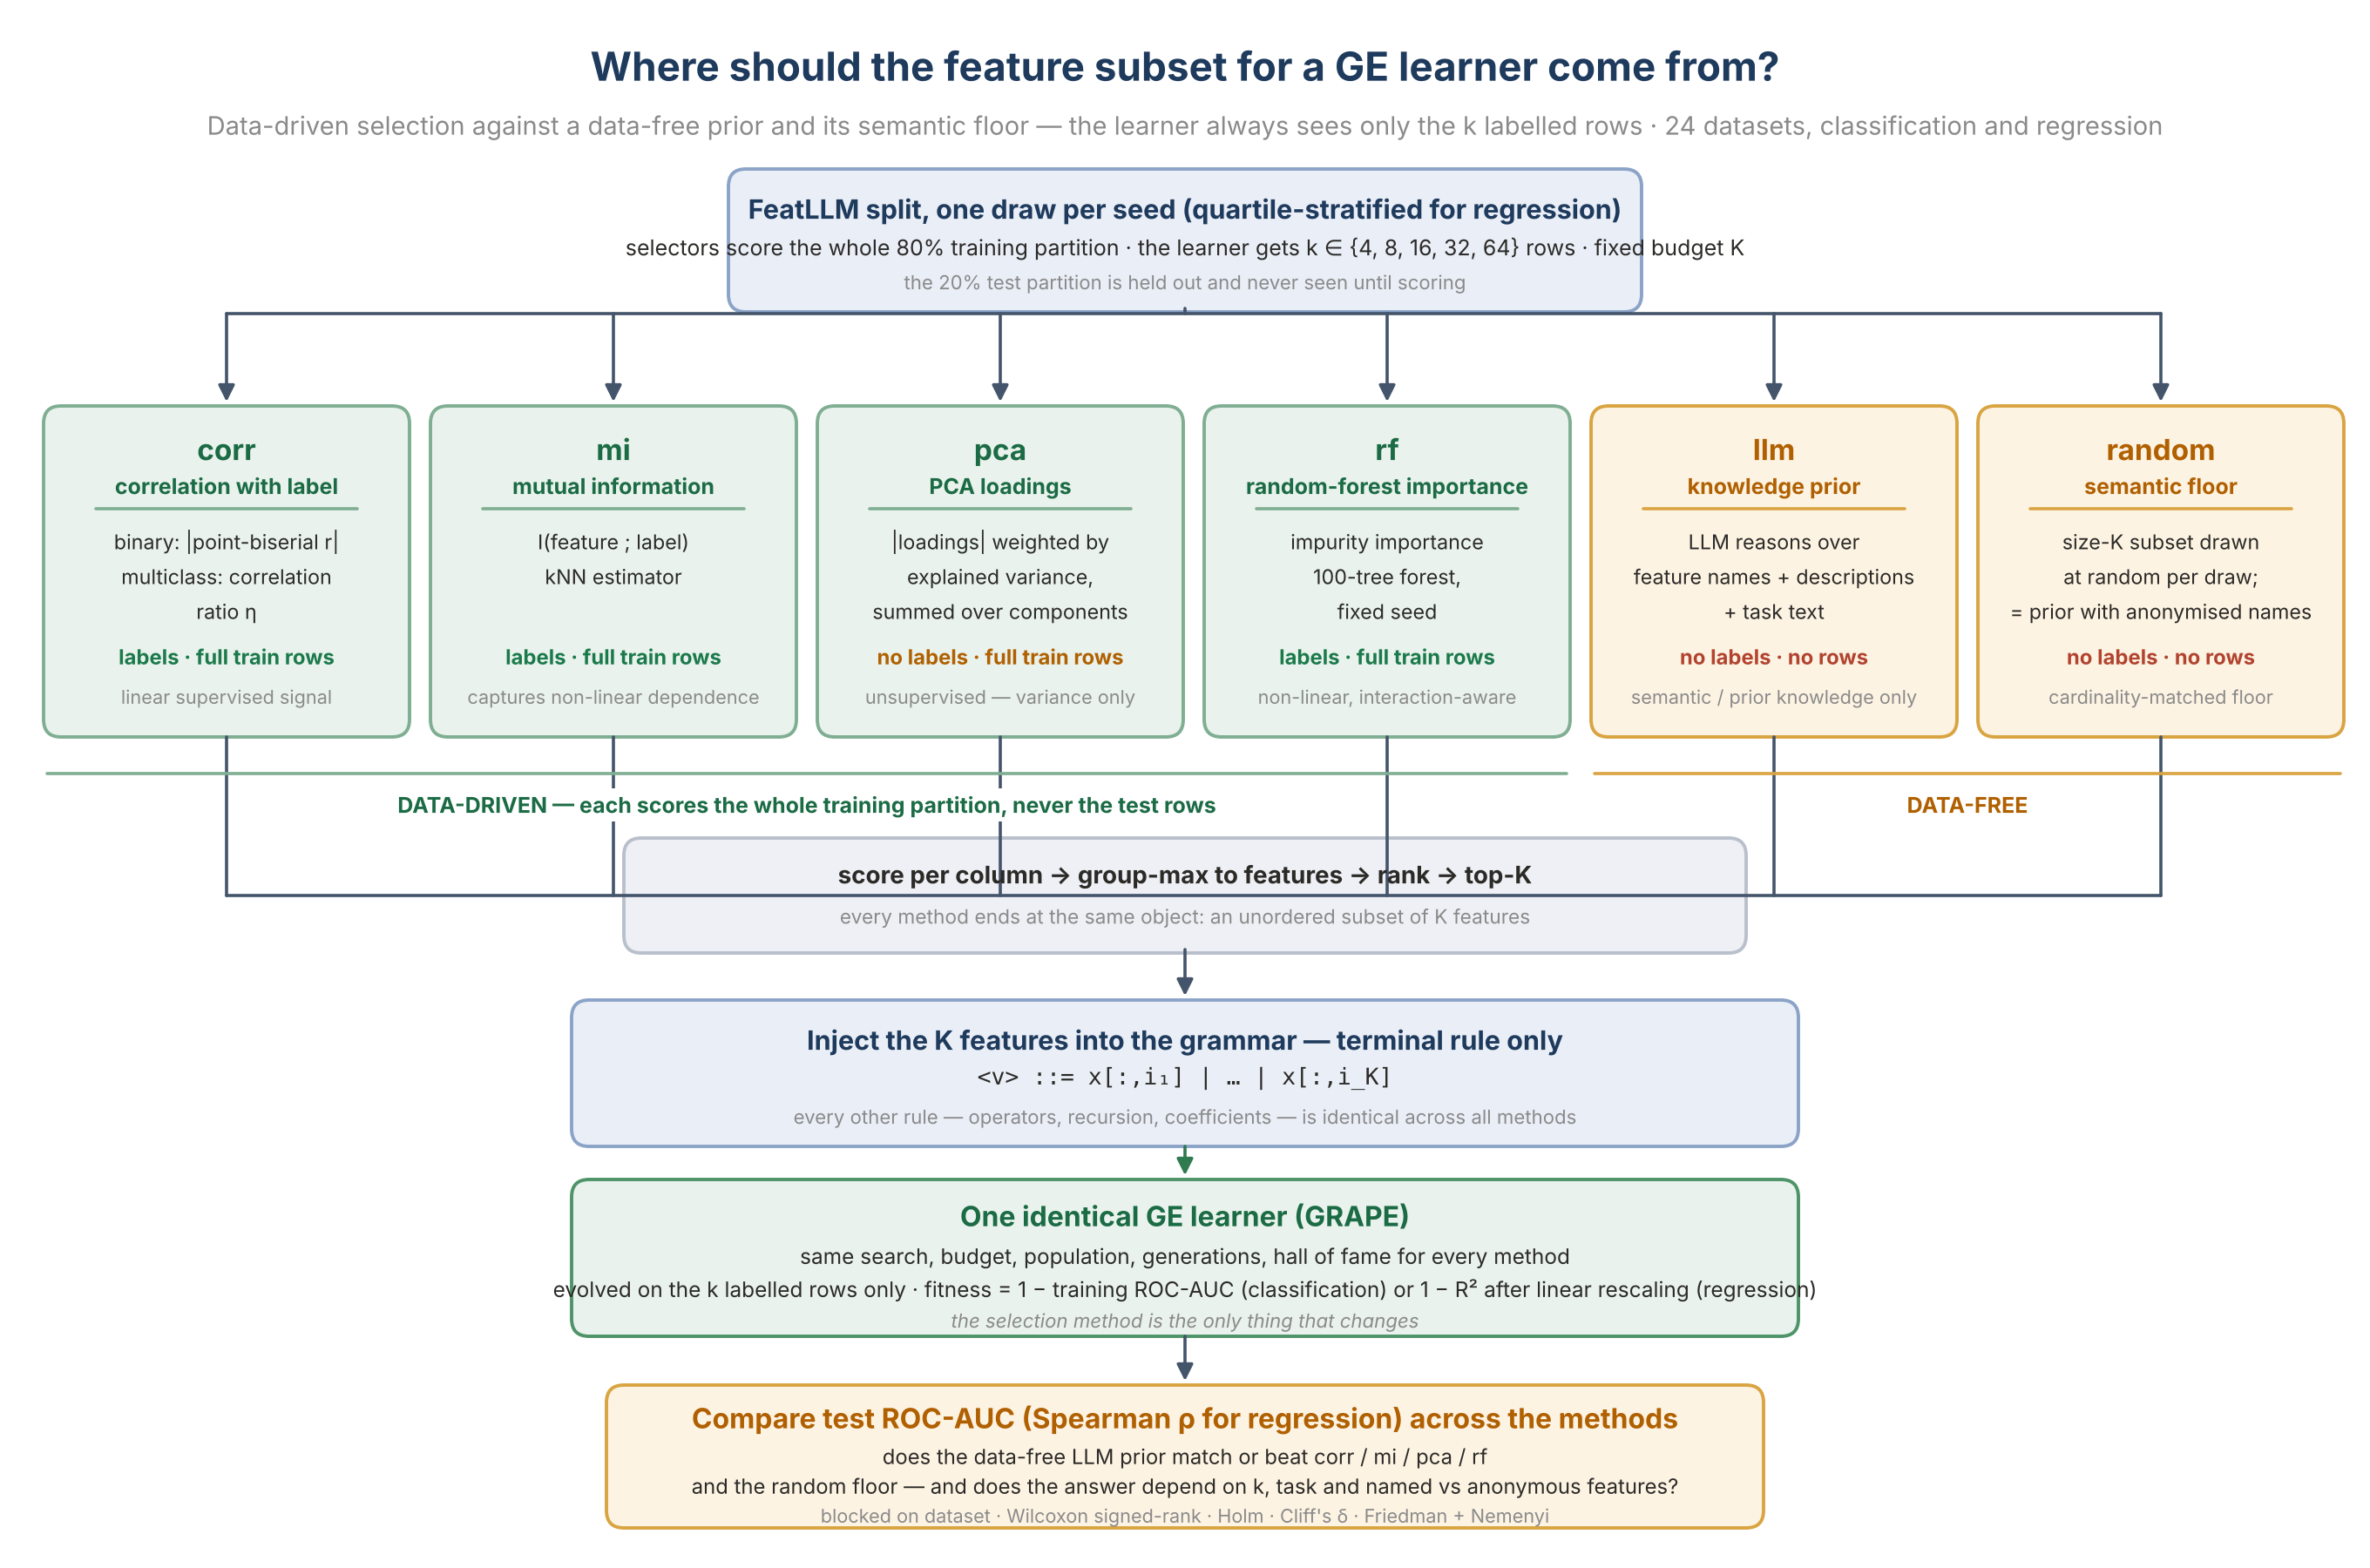

In [3]:
from IPython.display import Image, Markdown, display

display(Image("design_diagram.png", width=900))

## Campaign

Set `RUN_CAMPAIGN = True` to evolve the GE cells on this machine with all
cores but one. On a fresh checkout the eleven FeatLLM datasets are already
complete in the bundled results (the full-information campaign of
10 October 2026 under `results/`, the matched reference run of
2 October 2026 seeded into `results/matched/`), so what runs is the
thirteen added datasets: about 13 000 single-rule searches, roughly 14
CPU-hours at 4 s per search, which is an afternoon on eight processes or an
overnight run on four. The design-invariant methods (all features, LLM
prior, random subset) are shared between the two designs rather than
evolved twice. Completed cells are skipped on re-run, so the cell can be
interrupted and resumed.

Set `RUN_CAMPAIGN = False` to analyse whatever `results/` already holds without evolving anything.

In [4]:
RUN_CAMPAIGN = False

local = config.RESULTS_DIR / "fewshot.csv"
if RUN_CAMPAIGN or SMOKE:
    if DESIGN == "matched" and not local.exists() and not SMOKE:
        import shutil
        shutil.copy(config.REFERENCE_RUN, local)
        print("seeded results/matched/fewshot.csv from the bundled reference run")
    !"{sys.executable}" run_study.py share-invariant
    flags = ("--matched " if DESIGN == "matched" else "") + ("--smoke" if SMOKE else "")
    !"{sys.executable}" run_fewshot_parallel.py {flags}

In [5]:
!"{sys.executable}" run_study.py status

  adult                cla   420 / 420   done


  bank                 cla   420 / 420   done
  blood                cla   420 / 420   done
  car                  cla   420 / 420   done
  communities          cla   420 / 420   done


  credit_g             cla   420 / 420   done
  diabetes             cla   420 / 420   done
  heart                cla   420 / 420   done


  myocardial           cla   420 / 420   done
  cultivars            cla   420 / 420   done
  nhanes               cla   420 / 420   done
  breast_cancer        cla   420 / 420   done
  dermatology          cla   350 / 350   done
  ionosphere           cla   420 / 420   done


  spambase             cla   420 / 420   done
  optdigits            cla   280 / 280   done


  geo_music            reg   420 / 420   done
  mice_protein         cla   350 / 350   done
  parkinsons           reg   420 / 420   done
  student_performance  reg   420 / 420   done


  student_dropout      cla   420 / 420   done
  sonar                cla   420 / 420   done


  ames_housing         reg   420 / 420   done
  wine_quality         reg   420 / 420   done
  total                     9800 / 9800


## Check against the bundled reference

Under the matched design every reported method must reproduce the
reference cell for cell on the FeatLLM eleven: identical test score,
identical evolved phenotype. Under the full-information design only the
design-invariant methods (all features, LLM prior, random subset) are
expected to; the data-driven selectors differ by design. When both
campaigns exist, the invariant methods are also compared between them on
every dataset.

In [6]:
!"{sys.executable}" check_reference.py

against the bundled reference (FeatLLM eleven):
  cells compared:       4620 (local 9800, other 4620)
  identical score:      4620 / 4620 (max |diff| 0.00e+00)
  identical phenotypes: 4620 / 4620


against the other campaign (none|random|llm, all datasets):
  cells compared:       4200 (local 4200, other 4200)
  identical score:      4200 / 4200 (max |diff| 0.00e+00)
  identical phenotypes: 4200 / 4200


## Tables, tests, report and figures

`analyse_selectors.py` writes one folder per analysis family under
`results/<design>/analysis/` (classification is the primary family;
regression and the two name strata are secondary), plus the cross-family
tables; `report_selectors.py` writes `report.md` from those tables;
`selector_figures.py` draws the figures. `standalone_figures.py`
(per-method sheets and selector diagnostics) and `time_selectors.py`
(the selectors' own fitting cost) are optional and slower.

In [7]:
!"{sys.executable}" analyse_selectors.py

paired cells: 9800 / 9800



[classification] confirmatory contrasts:
shot    contrast  n_datasets  median_diff_pts  mean_diff_pts  wilcoxon_p  cliffs_delta   holm_p  significant_05  magnitude
   4 llm vs corr          16         3.069159       3.300610    0.057678      0.179688 0.115356           False      small
   4   llm vs mi          16         3.338815       2.872591    0.021393      0.210938 0.064178           False      small
   4  llm vs pca          16         2.340245       3.854394    0.013092      0.210938 0.052368           False      small
   4   llm vs rf          16         1.756101       1.563957    0.211426      0.093750 0.211426           False negligible
   8 llm vs corr          18         3.220163       4.108917    0.006577      0.216049 0.019730            True      small
   8   llm vs mi          18         2.880663       3.479677    0.015930      0.179012 0.019730            True      small
   8  llm vs pca          18         5.925099       6.971566    0.000328      0.339506 0.001312  

shot    contrast  n_datasets   favours  median_diff_pts   holm_p  confirmatory_significant  nemenyi_rank_gap  nemenyi_cd nemenyi_significant  agree         outcome
   4 llm vs corr          16 LLM prior         3.069159 0.115356                     False          1.625000    1.524998                True  False not significant
   4   llm vs mi          16 LLM prior         3.338815 0.064178                     False          1.437500    1.524998               False   True not significant
   4  llm vs pca          16 LLM prior         2.340245 0.052368                     False          1.562500    1.524998                True  False not significant
   4   llm vs rf          16 LLM prior         1.756101 0.211426                     False          0.687500    1.524998               False   True not significant
   8 llm vs corr          18 LLM prior         3.220163 0.019730                      True          1.111111    1.437782               False  False     significant
   8   llm vs mi

In [8]:
!"{sys.executable}" report_selectors.py
!"{sys.executable}" selector_figures.py

-> /home/claude/ge_selector_comparison/results/matched/analysis/report.md


  figures/matched/classification/fig_pooled_score_vs_shot.png


  figures/matched/classification/fig_pooled_score_vs_shot_all.png


  figures/matched/classification/fig_mean_rank_vs_shot.png


  figures/matched/classification/fig_mean_rank_vs_shot_all.png


  figures/matched/classification/fig_significance_confirmatory.png


... (117 outputs left out)

  figures/matched/per_dataset/fig_score_student_dropout.png


  figures/matched/per_dataset/fig_score_sonar.png


  figures/matched/per_dataset/fig_score_ames_housing.png


  figures/matched/per_dataset/fig_score_wine_quality.png
4 figure(s) skipped; re-run once the campaign completes


In [9]:
RUN_OPTIONAL = False
if RUN_OPTIONAL:
    !"{sys.executable}" standalone_figures.py
    !"{sys.executable}" time_selectors.py
    !"{sys.executable}" selector_figures.py

## Classification: pooled test ROC-AUC

Median across the classification datasets of per-dataset means over the
draws (x 100), single evolved rule. N is the number of datasets with the
level.

In [10]:
A = config.RESULTS_DIR / "analysis"
F = config.FIGURES_DIR
NAMES = {"none": "All features", "corr": "Correlation", "mi": "Mutual information",
         "pca": "PCA loadings", "rf": "RF importance", "llm": "LLM prior", "random": "Random subset"}
METHODS = list(config.FEWSHOT_CONTROLS)
PRIMARY = list(config.FEWSHOT_PRIMARY_CONTROLS)

def pooled_table(family):
    pooled = pd.read_csv(A / family / "pooled_summary.csv", dtype={"shot": str})
    shots = [s for s in config.ALL_SHOTS if s in set(pooled.shot)]
    ns = pooled.groupby("shot").n_datasets.max()
    tbl = (pooled.pivot(index="control", columns="shot", values="pooled_median")
                 .reindex(METHODS)[shots] * 100).round(1)
    tbl.columns = [f"k = {s} (N = {ns[s]})" if s != "full" else f"full (N = {ns[s]})" for s in shots]
    tbl.index = tbl.index.map(NAMES); tbl.index.name = "Method"
    return tbl

pooled_table("classification")

,k = 4 (N = 16),k = 8 (N = 18),k = 16 (N = 19),k = 32 (N = 19),k = 64 (N = 19),full (N = 19)
Method,,,,,,
All features,57.3,60.9,66.9,74.4,80.2,86.9
Correlation,58.0,61.2,70.0,73.5,79.5,87.3
Mutual information,60.3,62.4,67.9,74.0,81.4,87.3
PCA loadings,59.4,58.9,64.0,71.4,74.7,80.3
RF importance,58.0,63.3,70.0,74.4,79.2,88.3
LLM prior,63.0,65.0,70.6,75.1,81.6,87.4
Random subset,58.6,62.5,65.7,70.5,73.3,81.4


## Classification: omnibus and mean ranks

Friedman test over the five selection methods blocked on dataset, with the
Nemenyi critical difference for that level's N. Rank 1 is best.

In [11]:
def rank_table(family):
    fn = pd.read_csv(A / family / "friedman_nemenyi_primary.csv", dtype={"shot": str})
    ranks = fn.set_index("shot")[[f"rank_{m}" for m in PRIMARY]].round(2)
    ranks.columns = [NAMES[m] for m in PRIMARY]
    ranks.insert(0, "N", fn.set_index("shot").n_datasets)
    ranks["Friedman p"] = fn.set_index("shot").friedman_p.round(3)
    ranks["CD"] = fn.set_index("shot").nemenyi_cd.round(2)
    return ranks

rank_table("classification")

,N,Correlation,Mutual information,PCA loadings,RF importance,LLM prior,Friedman p,CD
shot,,,,,,,,
4,16,3.56,3.38,3.50,2.62,1.94,0.013,1.52
8,18,3.22,3.03,3.83,2.81,2.11,0.023,1.44
16,19,2.50,3.18,4.26,2.97,2.08,0.000,1.40
32,19,2.87,3.03,4.26,2.50,2.34,0.001,1.40
64,19,2.61,2.97,4.42,3.03,1.97,0.000,1.40


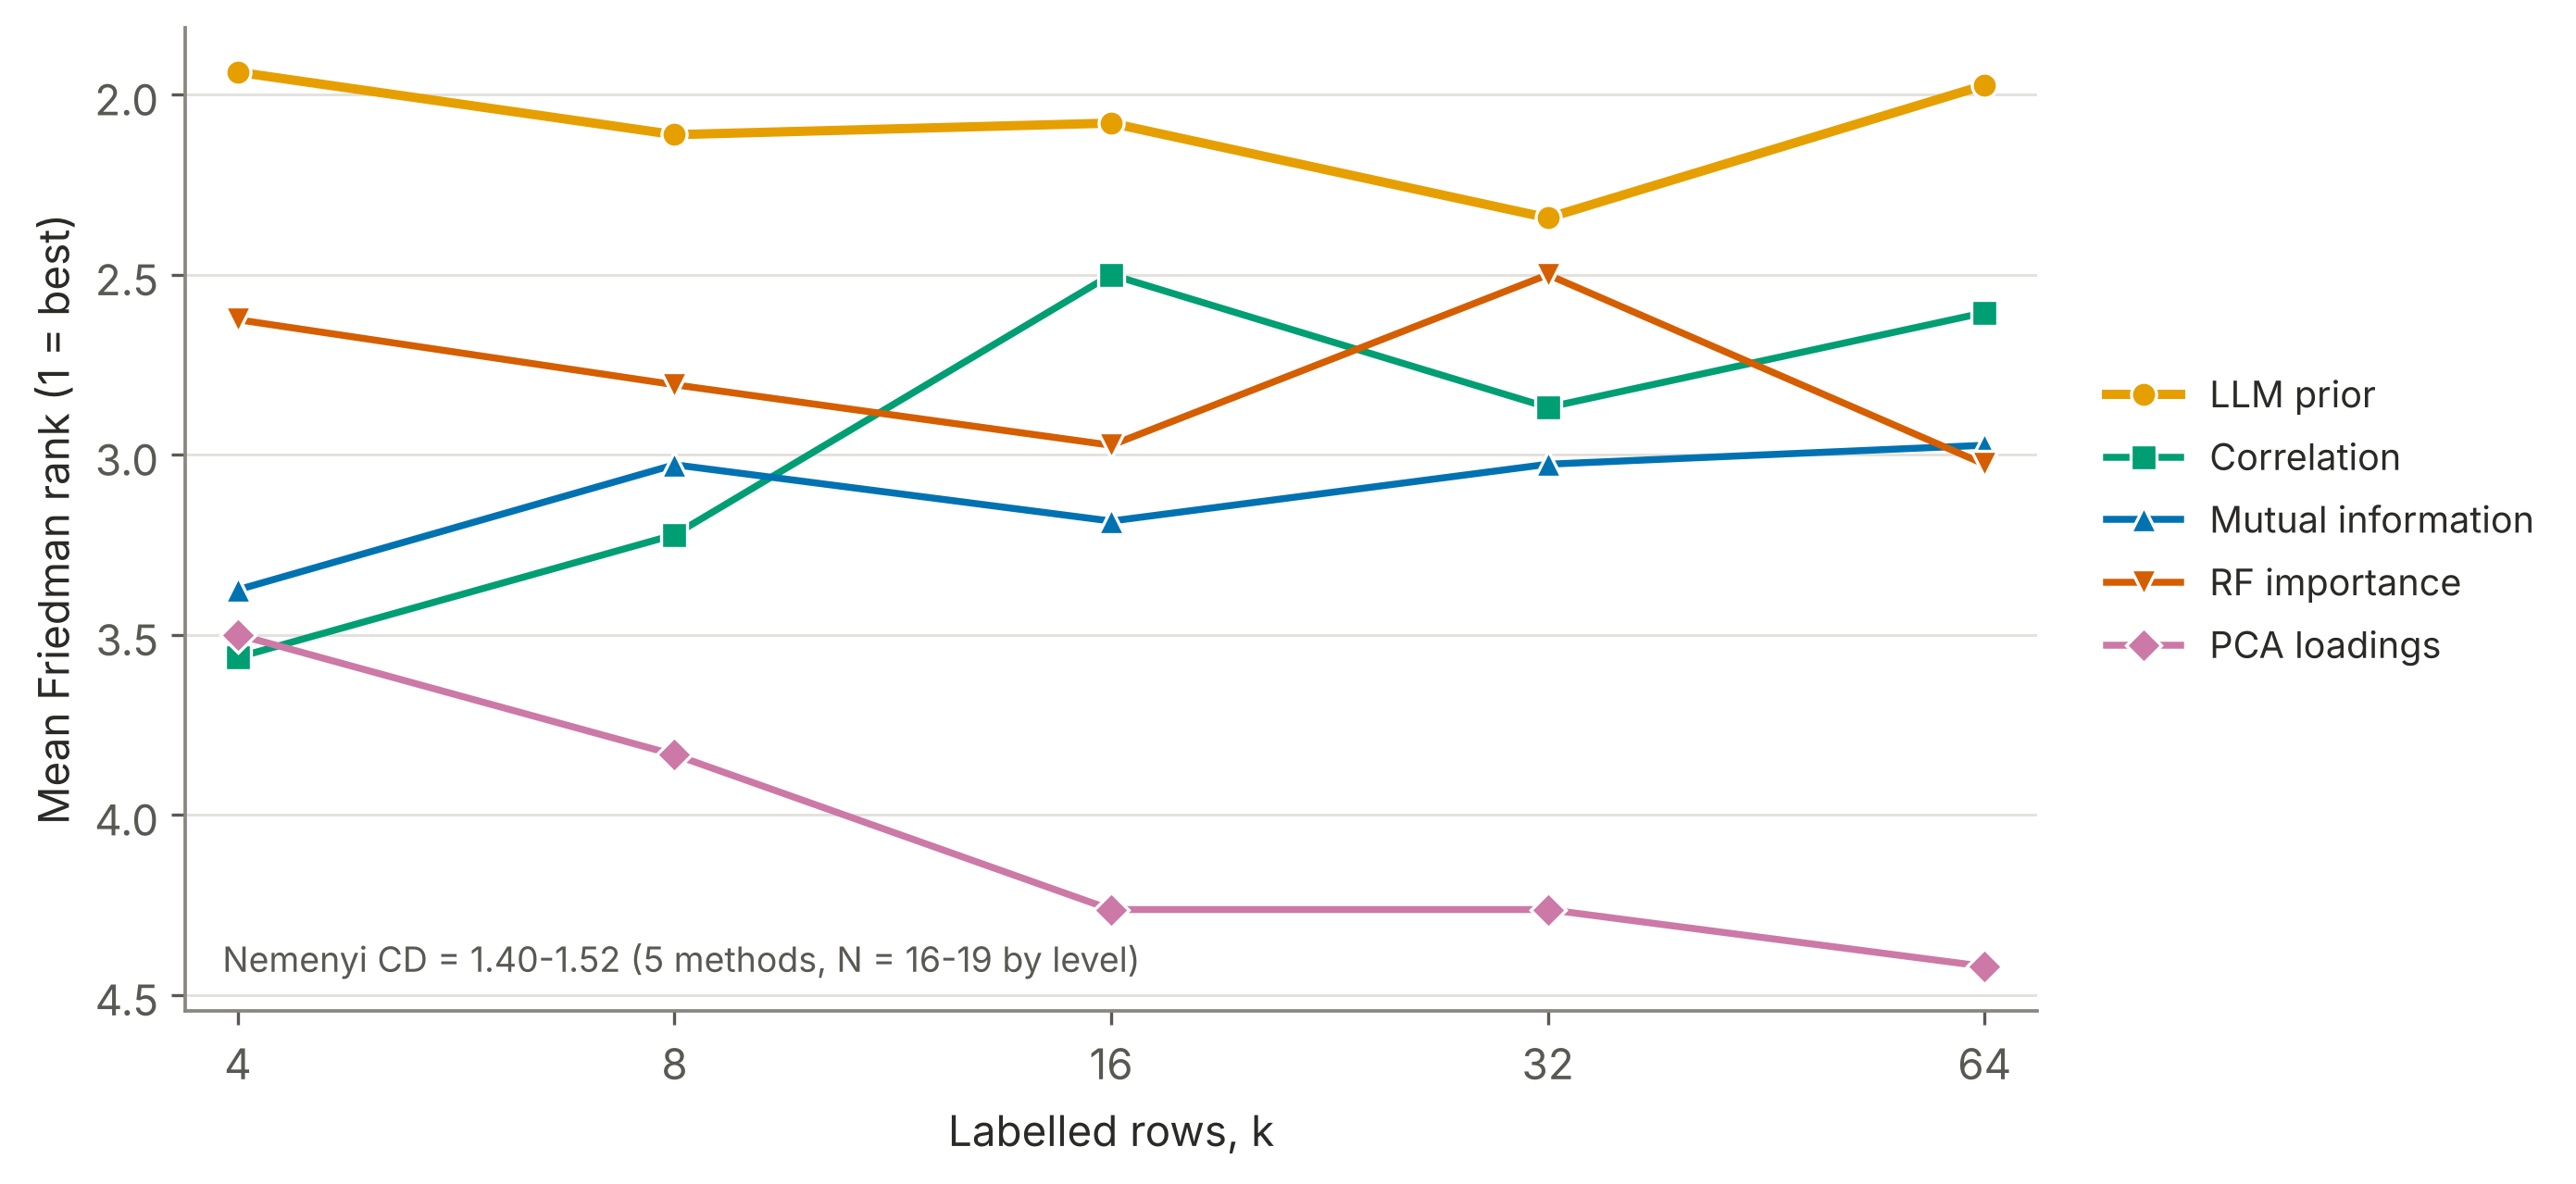

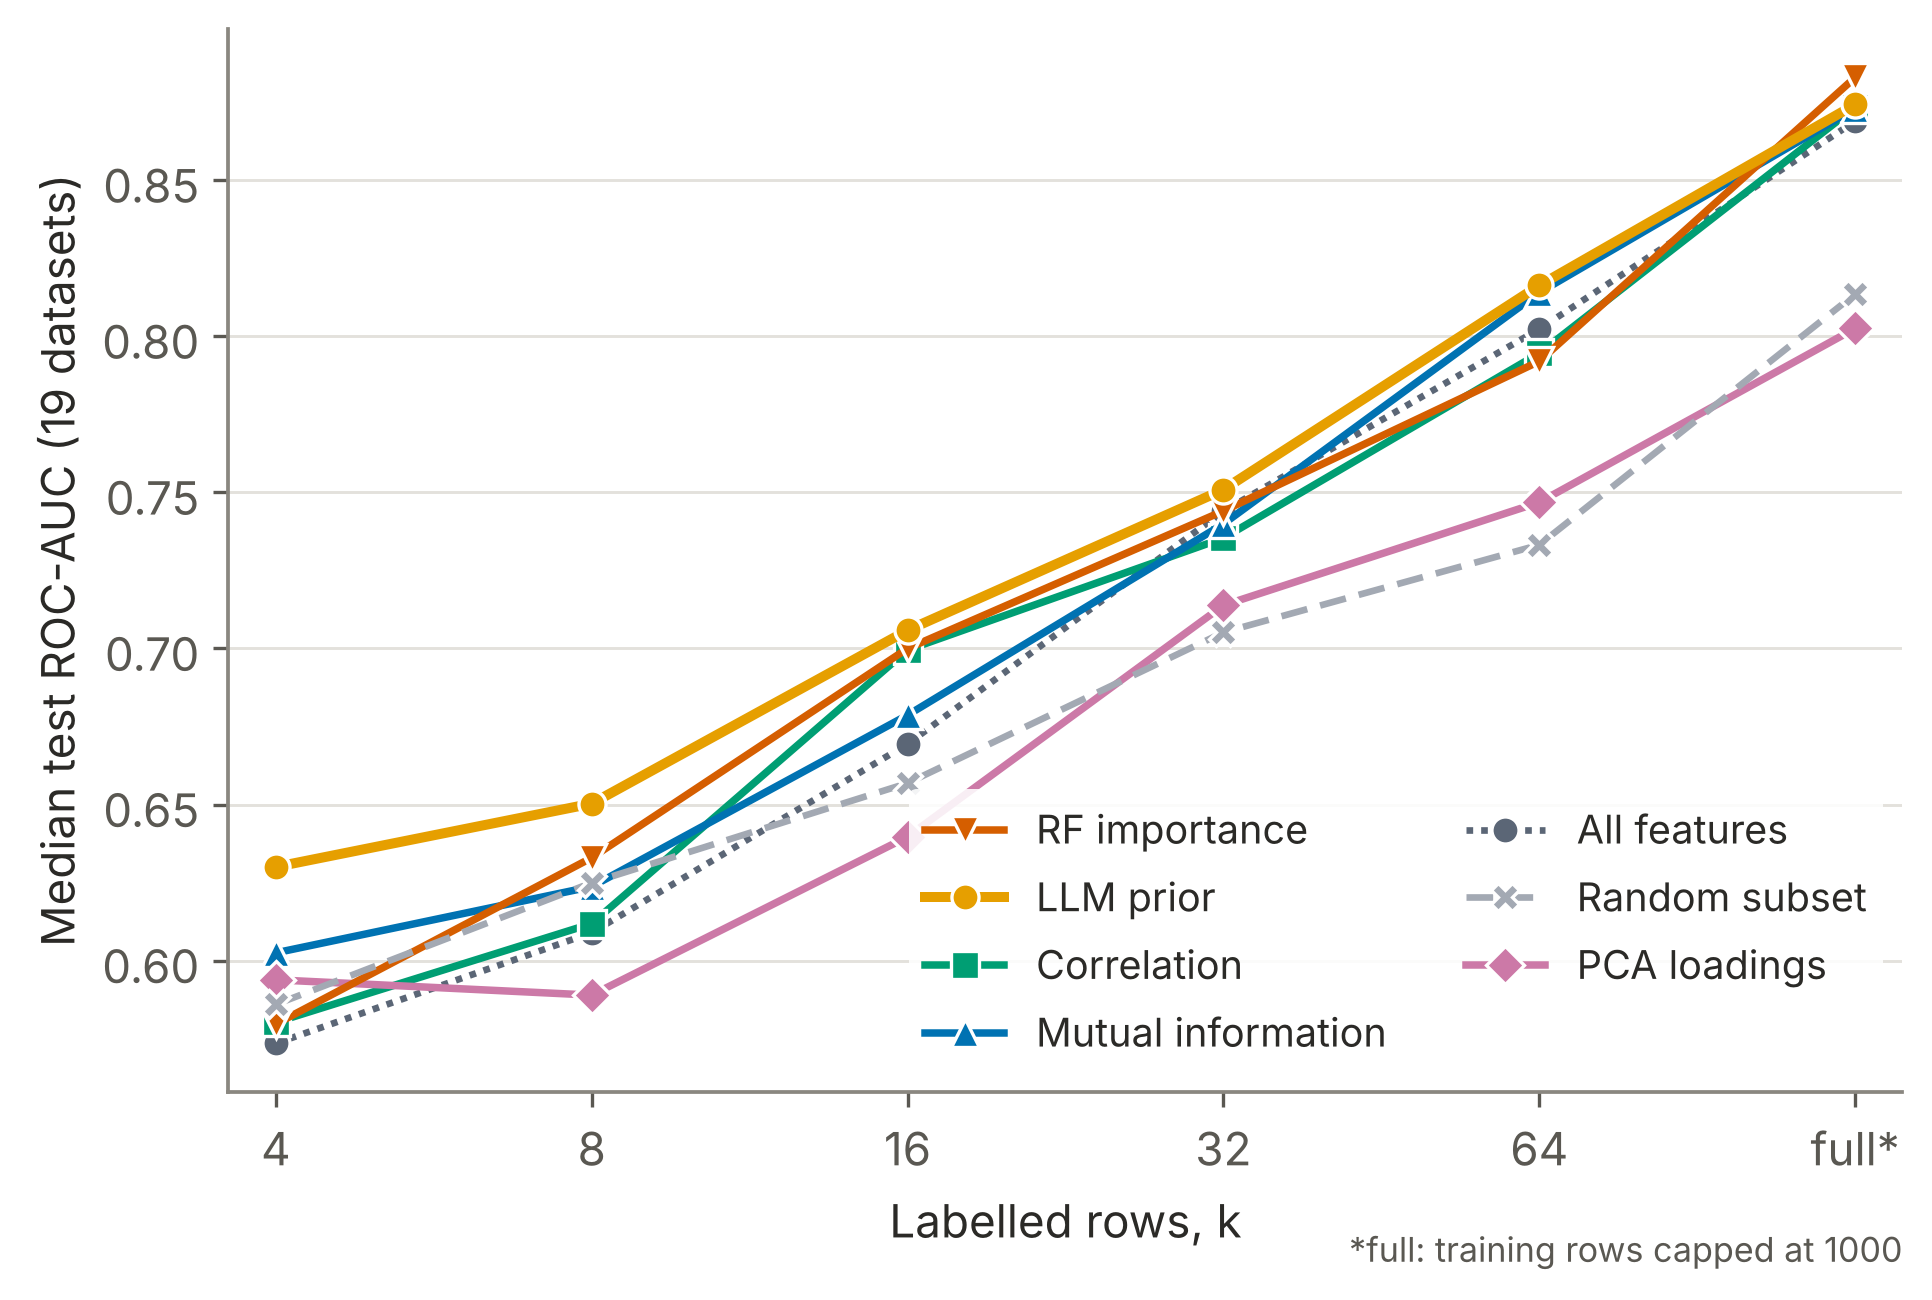

In [12]:
display(Image(str(F / "classification" / "fig_mean_rank_vs_shot.png"), width=820))
display(Image(str(F / "classification" / "fig_pooled_score_vs_shot_all.png"), width=760))

## Classification: confirmatory contrasts and the semantic floor

The LLM prior against each classical selector at each budget: two-sided
Wilcoxon signed-rank over the datasets, Holm within the budget, Cliff's
delta; positive median differences favour the prior. The Nemenyi columns
give the post hoc reading of the same pair. The semantic floor is the LLM
prior against the size-K random subset, Holm across the few-shot levels:
for a prior that never sees data, anonymised names leave no information
about the columns, so this contrast is the semantic contribution of the
prior at matched cardinality.

In [13]:
def summary_table(family):
    summ = pd.read_csv(A / family / "significance_summary.csv", dtype={"shot": str})
    summ["contrast"] = summ.contrast.map(lambda s: "LLM prior vs " + NAMES[s.split(" vs ")[1]])
    return summ[["shot", "contrast", "n_datasets", "median_diff_pts", "holm_p", "outcome",
                 "nemenyi_rank_gap", "nemenyi_cd", "nemenyi_significant"]].round(3)

summary_table("classification")

,shot,contrast,n_datasets,median_diff_pts,holm_p,outcome,nemenyi_rank_gap,nemenyi_cd,nemenyi_significant
0,4,LLM prior vs Correlation,16,3.069,0.115,not significant,1.625,1.525,True
1,4,LLM prior vs Mutual information,16,3.339,0.064,not significant,1.438,1.525,False
2,4,LLM prior vs PCA loadings,16,2.340,0.052,not significant,1.562,1.525,True
3,4,LLM prior vs RF importance,16,1.756,0.211,not significant,0.688,1.525,False
4,8,LLM prior vs Correlation,18,3.220,0.020,significant,1.111,1.438,False
5,8,LLM prior vs Mutual information,18,2.881,0.020,significant,0.917,1.438,False
6,8,LLM prior vs PCA loadings,18,5.925,0.001,significant,1.722,1.438,True
7,8,LLM prior vs RF importance,18,3.567,0.020,significant,0.694,1.438,False
8,16,LLM prior vs Correlation,19,1.507,0.170,not significant,0.421,1.399,False
9,16,LLM prior vs Mutual information,19,3.432,0.022,significant,1.105,1.399,False


In [14]:
floor = pd.read_csv(A / "classification" / "semantic_floor_wilcoxon.csv", dtype={"shot": str})
floor[["shot", "n_datasets", "median_diff_pts", "wilcoxon_p", "holm_p", "cliffs_delta", "magnitude", "significant_05"]].round(3)

,shot,n_datasets,median_diff_pts,wilcoxon_p,holm_p,cliffs_delta,magnitude,significant_05
0,4,16,4.424,0.000,0.000,0.312,small,True
1,8,18,4.598,0.001,0.001,0.204,small,True
2,16,19,3.976,0.008,0.008,0.263,small,True
3,32,19,3.461,0.000,0.000,0.235,small,True
4,64,19,4.519,0.000,0.000,0.252,small,True
5,full,19,3.446,0.000,0.000,0.235,small,True


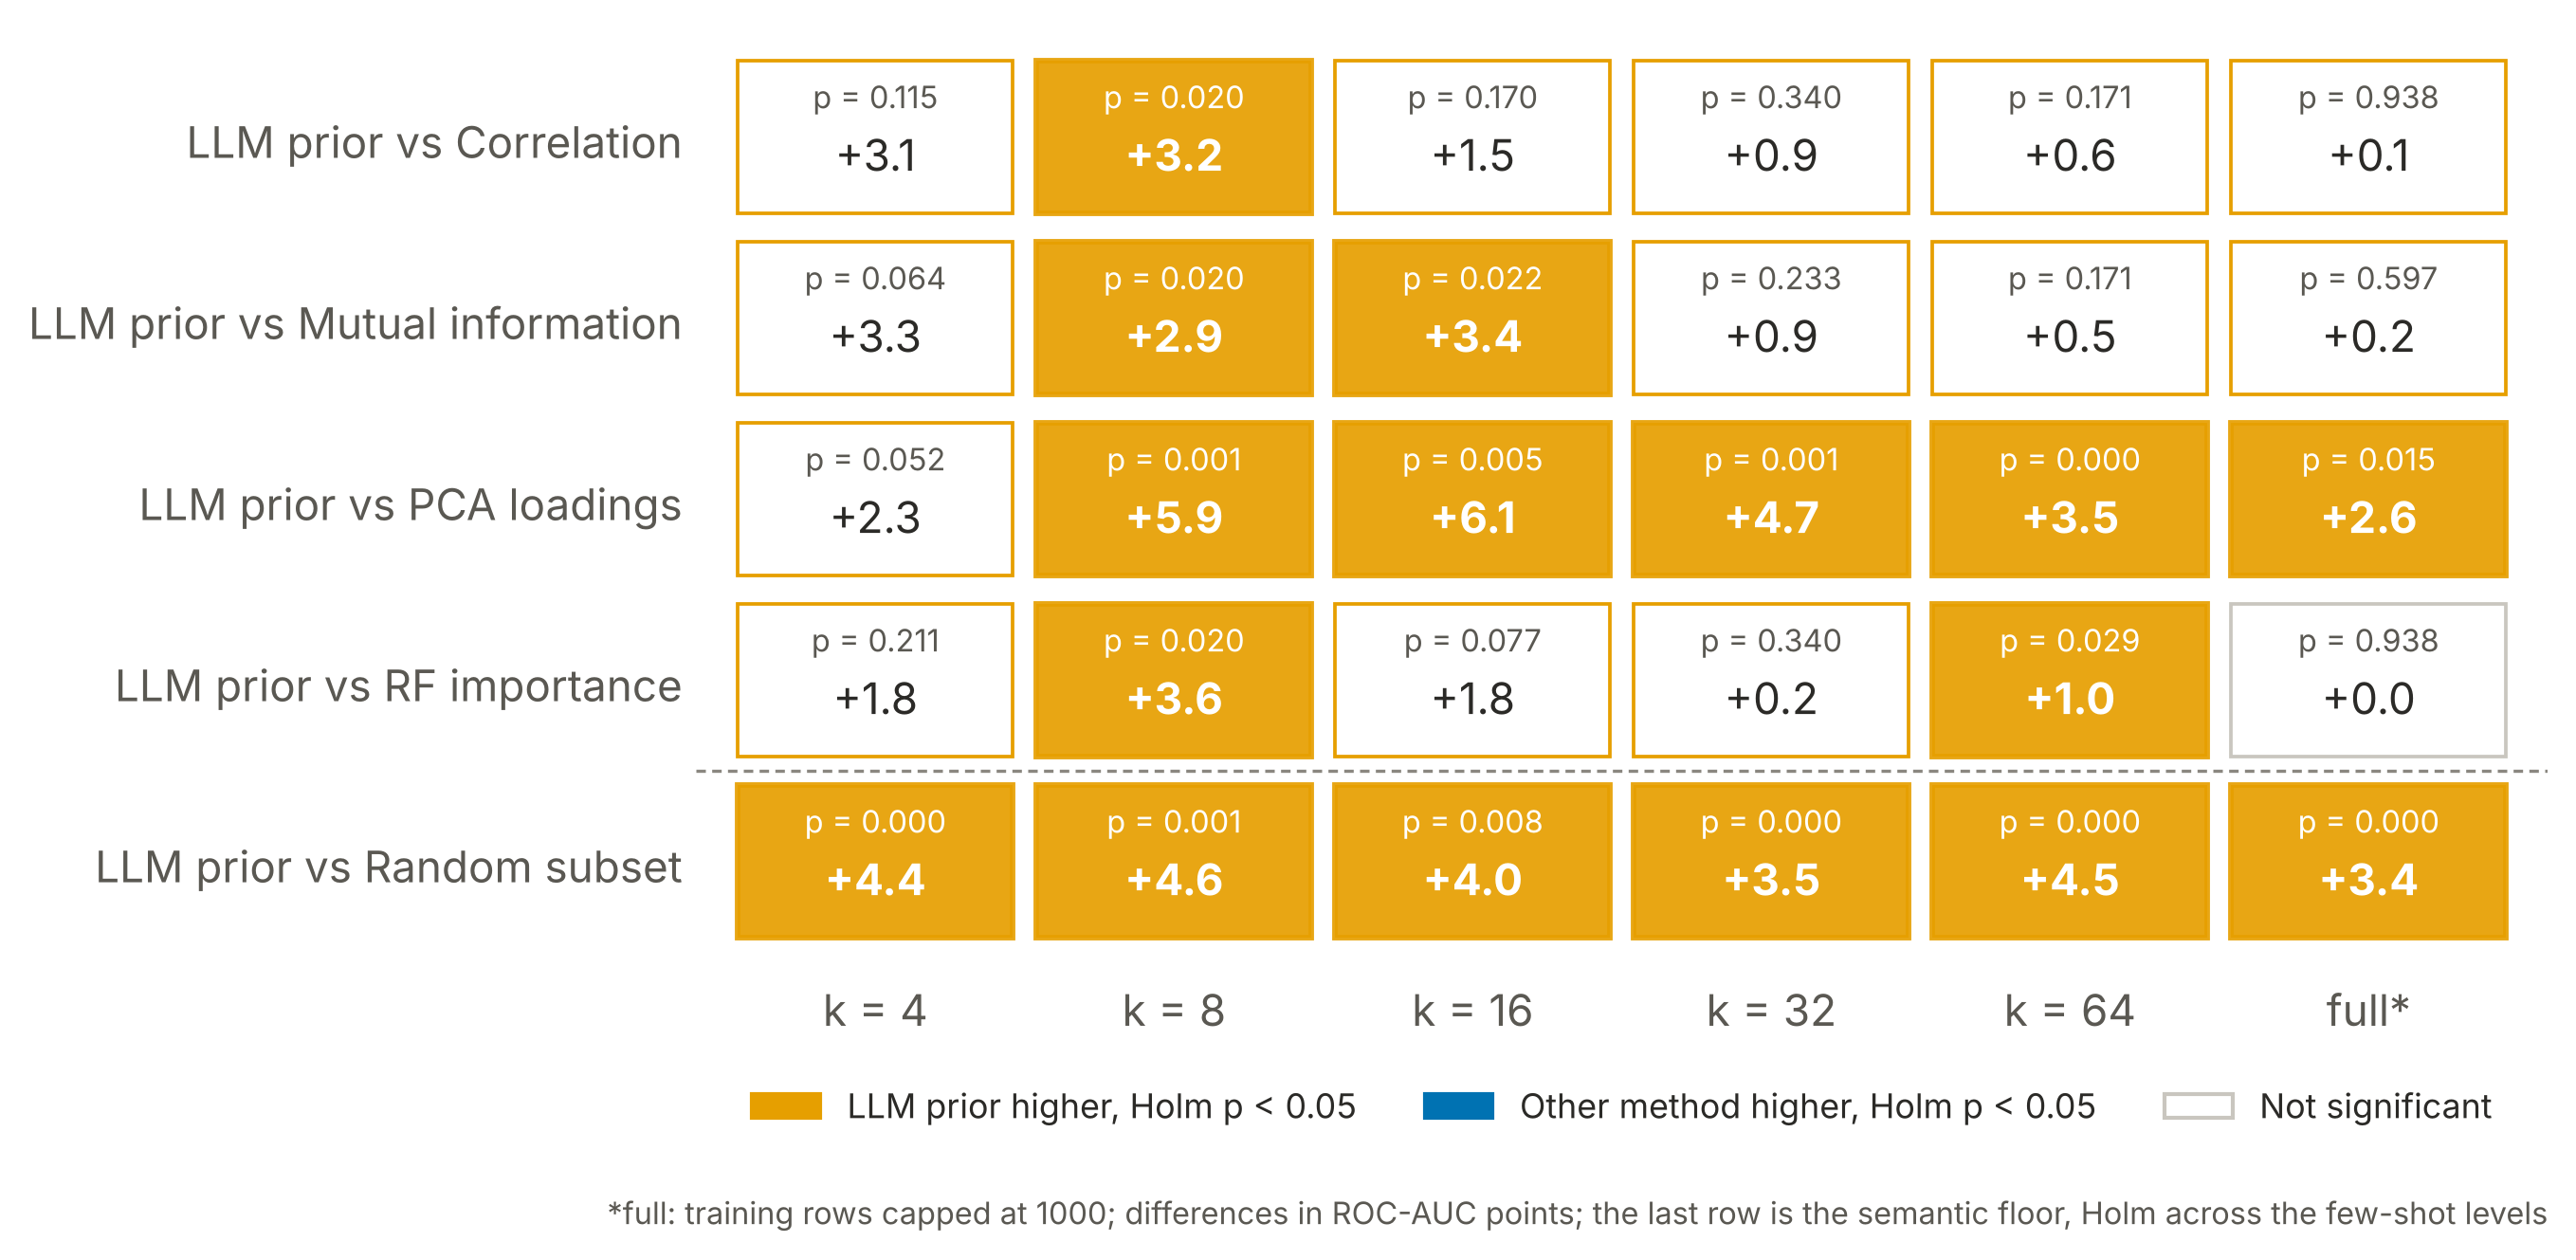

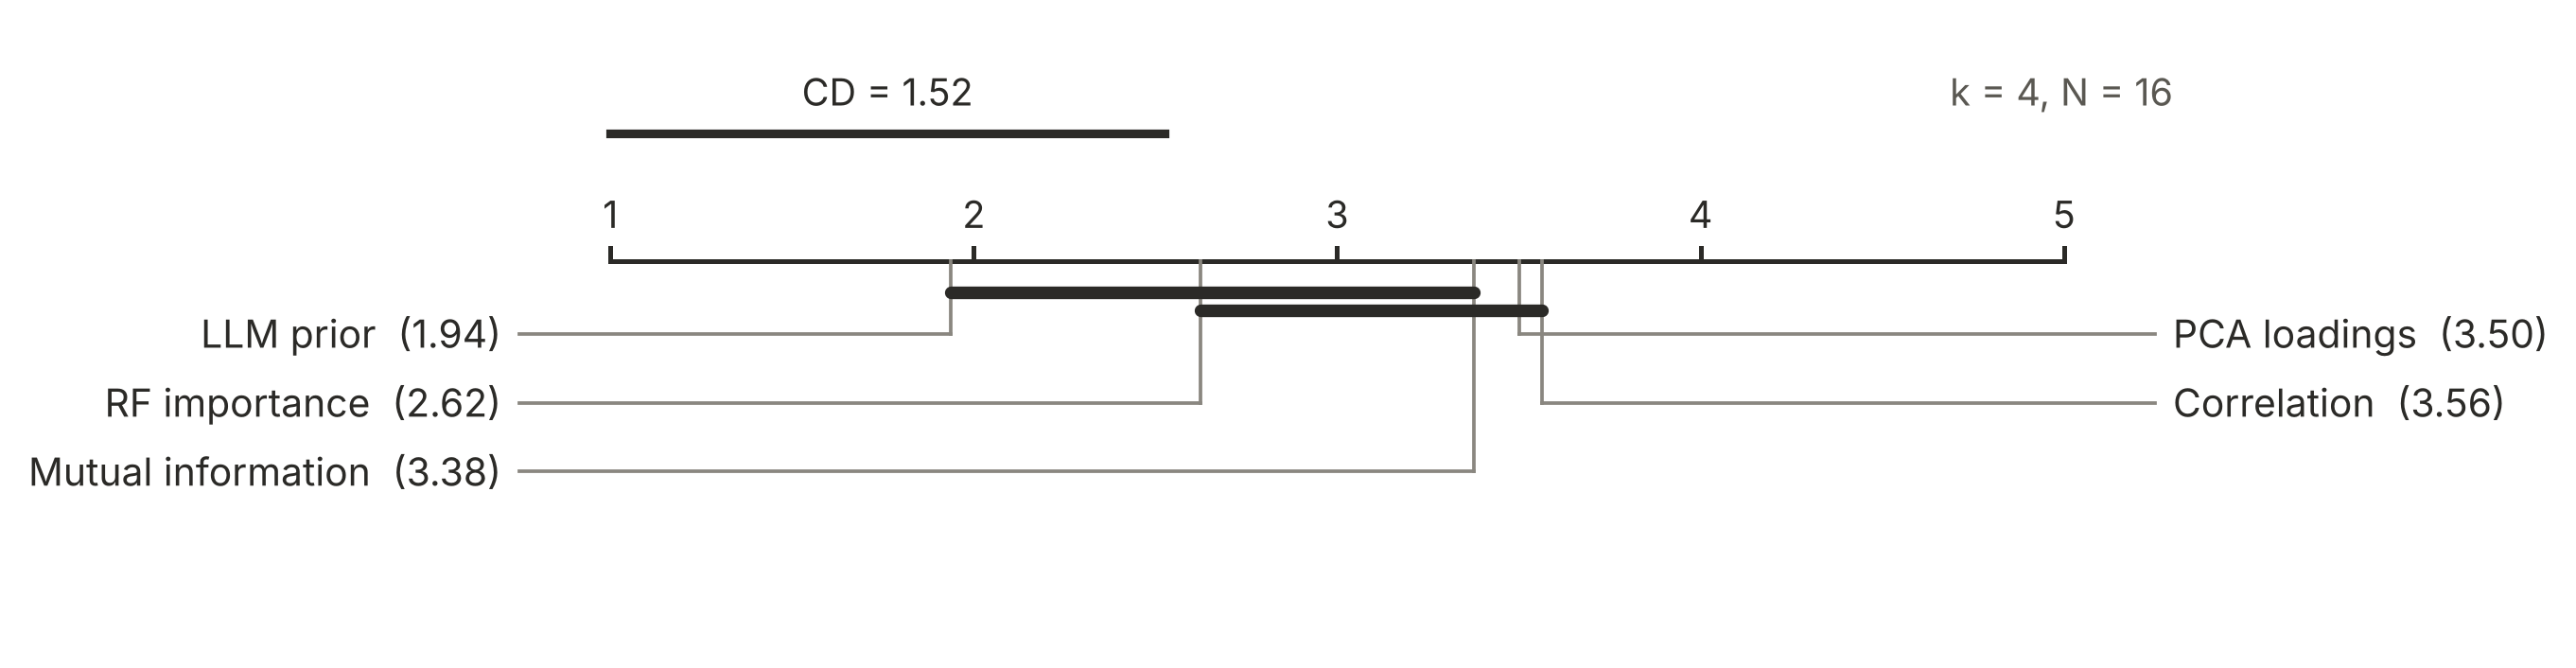

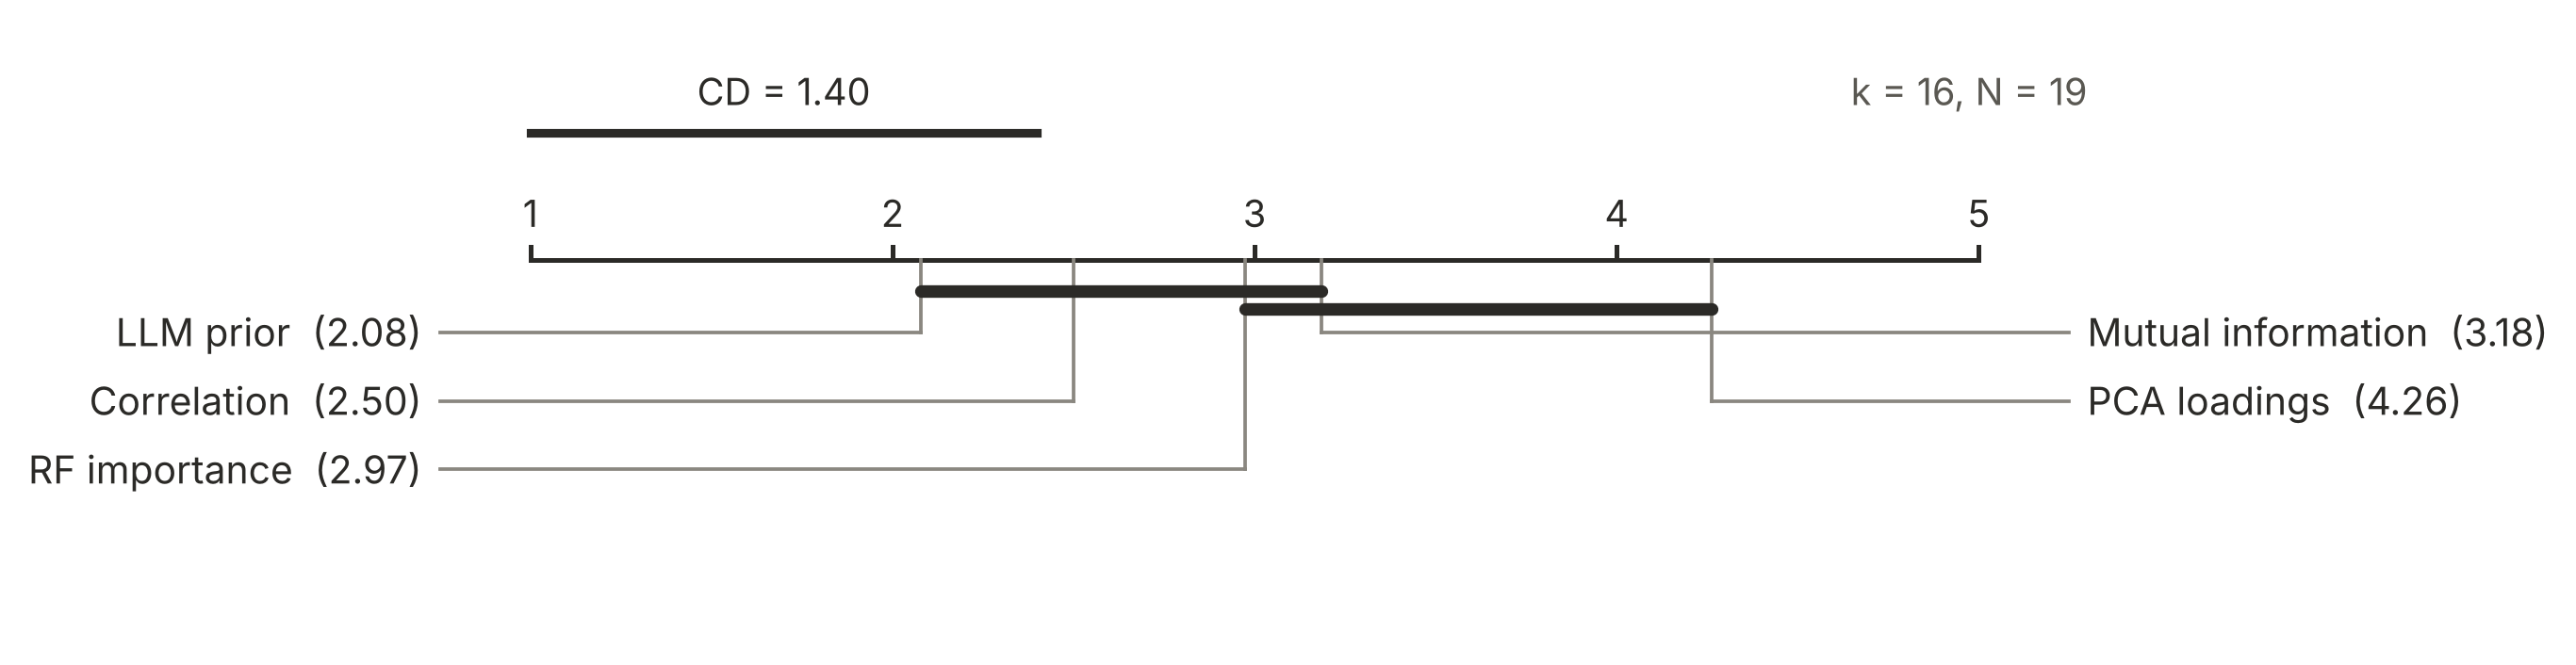

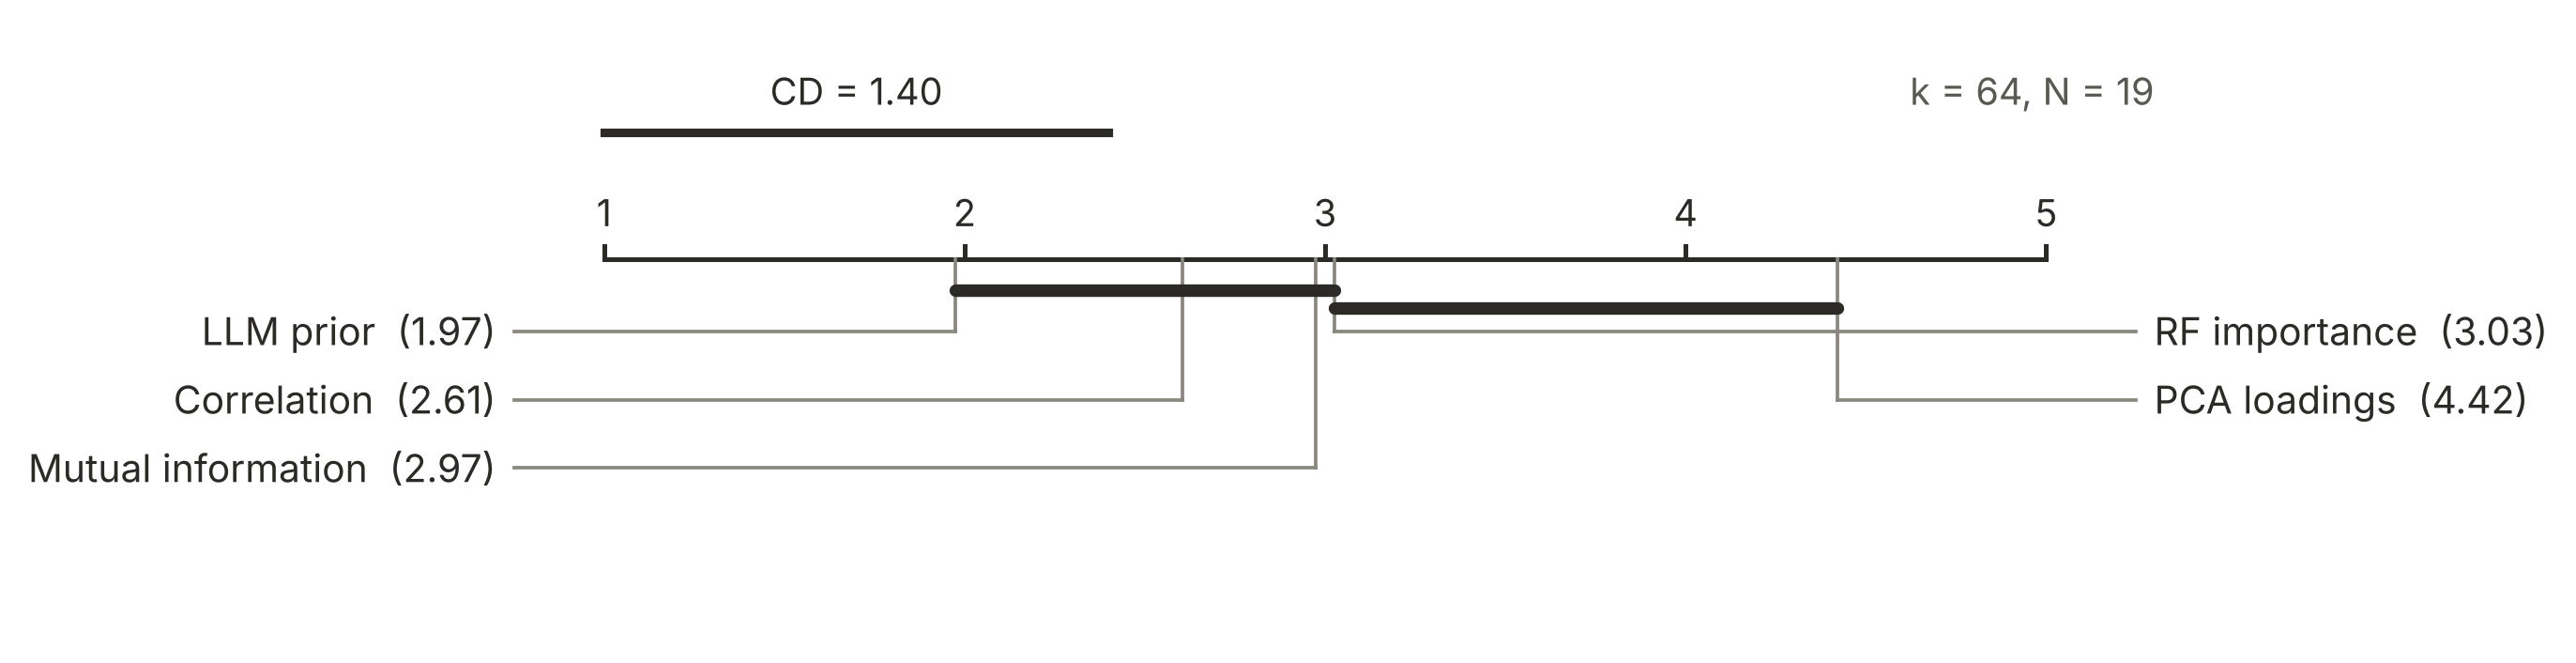

In [15]:
display(Image(str(F / "classification" / "fig_significance_confirmatory.png"), width=820))
for s in [x for x in ("4", "16", "64") if (F / "classification" / f"fig_cd_shot_{x}.png").exists()]:
    display(Image(str(F / "classification" / f"fig_cd_shot_{s}.png"), width=760))

## Semantic-anchor moderator

The LLM prior minus the best data-driven selector on each dataset, by
stratum: datasets whose feature names carry domain meaning against those
with anonymous names (ionosphere, optical digits, geographical music,
sonar). The named stratum is analysed as its own family
(`classification_named`); the anonymous stratum is too small for a test
and is reported descriptively.

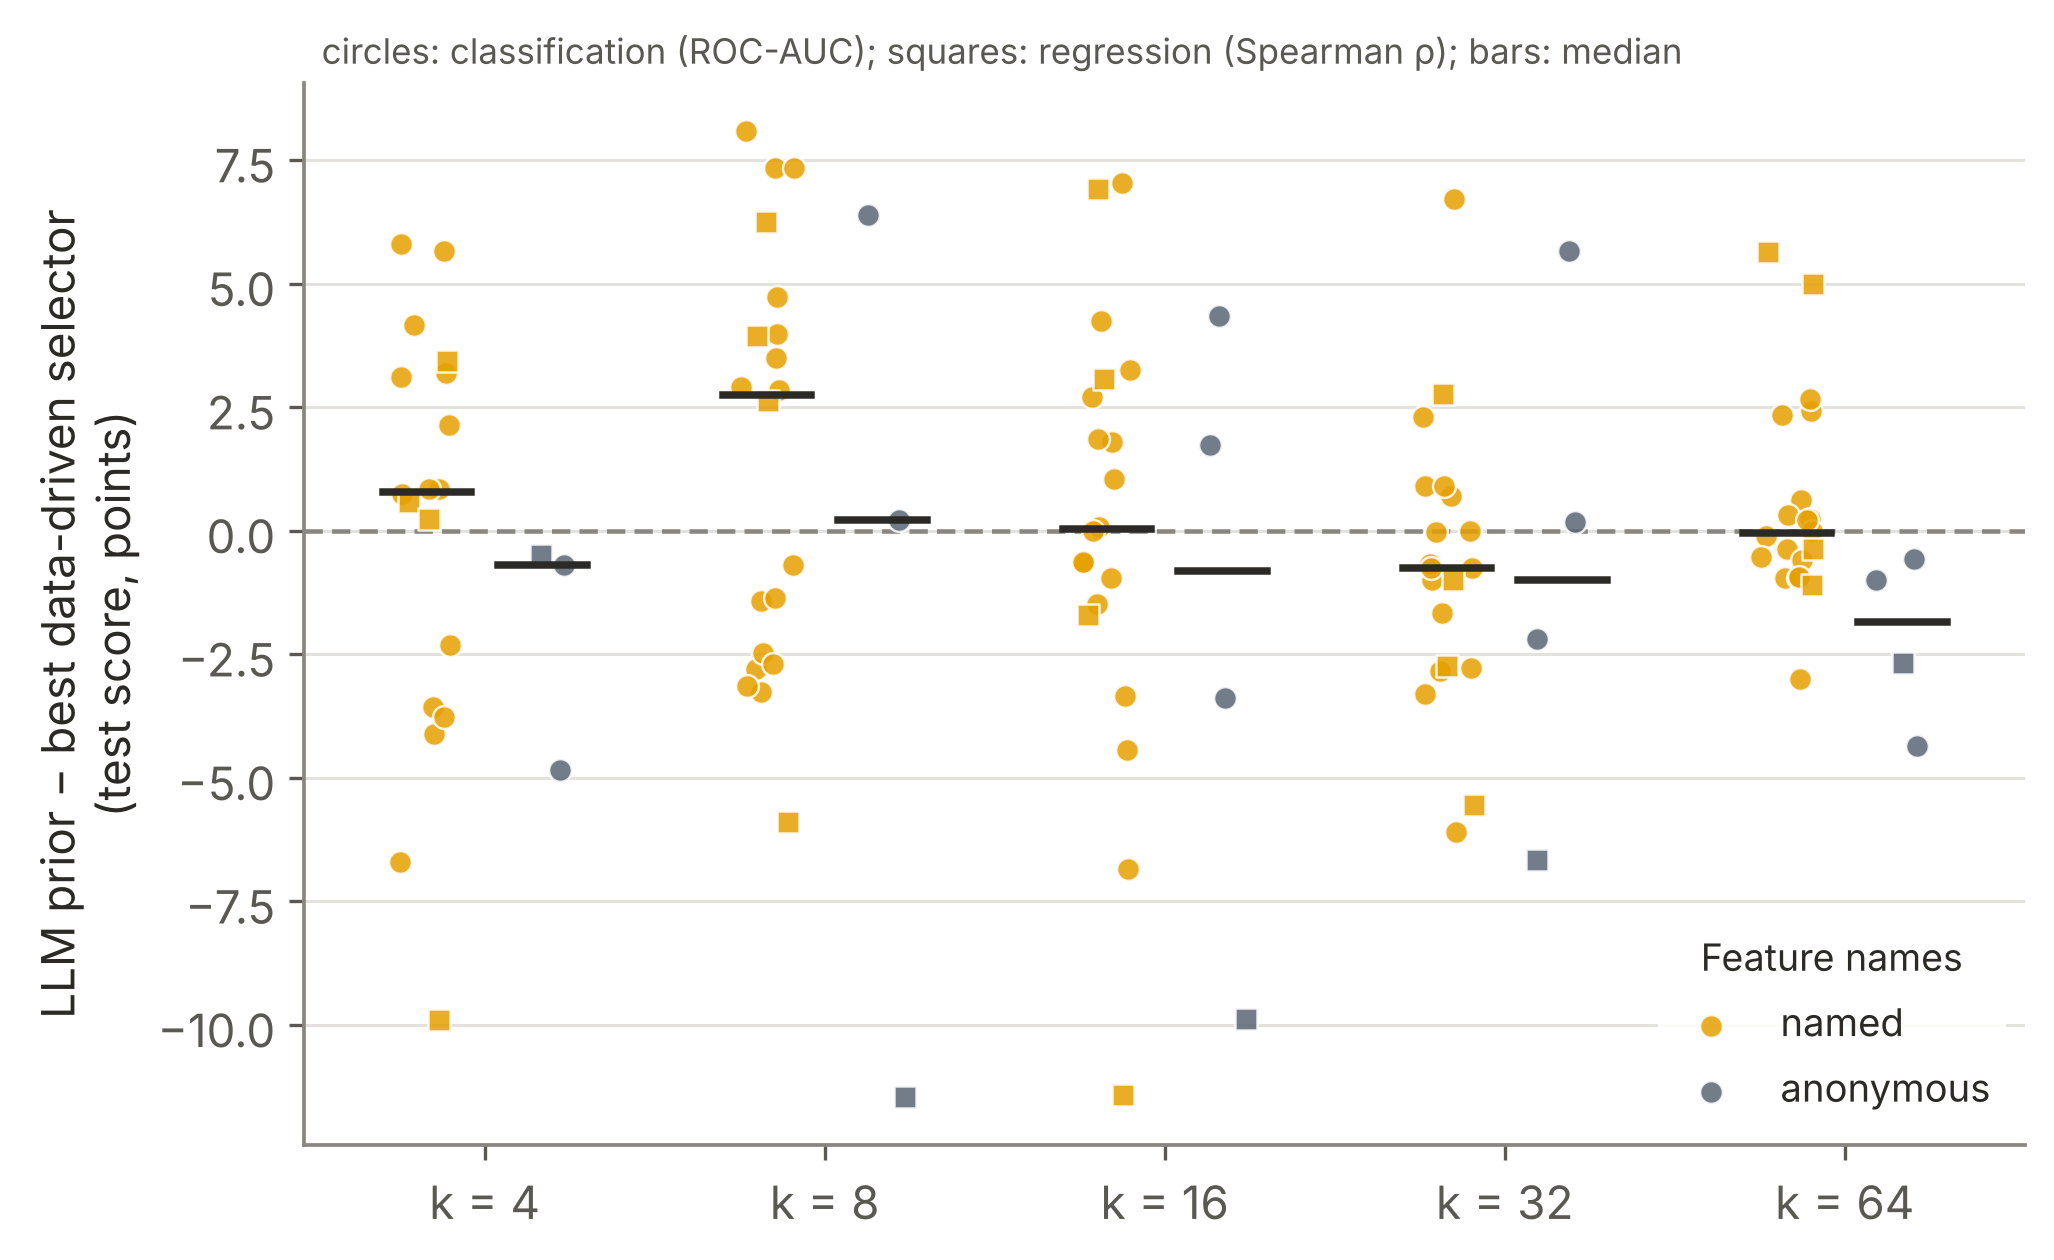

**classification_named**

,shot,contrast,n_datasets,median_diff_pts,holm_p,outcome,nemenyi_rank_gap,nemenyi_cd,nemenyi_significant
0,4,LLM prior vs Correlation,14,3.069,0.071,not significant,1.929,1.630,True
1,4,LLM prior vs Mutual information,14,3.429,0.032,significant,1.786,1.630,True
2,4,LLM prior vs PCA loadings,14,3.069,0.016,significant,1.786,1.630,True
3,4,LLM prior vs RF importance,14,2.304,0.135,not significant,0.929,1.630,False
4,8,LLM prior vs Correlation,16,2.746,0.075,not significant,0.875,1.525,False
5,8,LLM prior vs Mutual information,16,2.881,0.075,not significant,0.719,1.525,False
6,8,LLM prior vs PCA loadings,16,5.360,0.005,significant,1.688,1.525,True
7,8,LLM prior vs RF importance,16,3.229,0.075,not significant,0.469,1.525,False
8,16,LLM prior vs Correlation,16,0.787,0.281,not significant,0.375,1.525,False
9,16,LLM prior vs Mutual information,16,2.930,0.069,not significant,1.062,1.525,False


**classification_anonymous**

,shot,contrast,n_datasets,median_diff_pts,holm_p,outcome,nemenyi_rank_gap,nemenyi_cd,nemenyi_significant
0,4,LLM prior vs Correlation,2,-0.292,1.0,not significant,NaN,NaN,NaN
1,4,LLM prior vs Mutual information,2,-2.066,1.0,not significant,NaN,NaN,NaN
2,4,LLM prior vs PCA loadings,2,-0.861,1.0,not significant,NaN,NaN,NaN
3,4,LLM prior vs RF importance,2,-0.954,1.0,not significant,NaN,NaN,NaN
4,8,LLM prior vs Correlation,2,7.238,1.0,not significant,NaN,NaN,NaN
5,8,LLM prior vs Mutual information,2,4.104,1.0,not significant,NaN,NaN,NaN
6,8,LLM prior vs PCA loadings,2,5.925,1.0,not significant,NaN,NaN,NaN
7,8,LLM prior vs RF importance,2,5.346,1.0,not significant,NaN,NaN,NaN
8,16,LLM prior vs Correlation,3,2.604,1.0,not significant,0.667,3.522,False
9,16,LLM prior vs Mutual information,3,4.341,1.0,not significant,1.333,3.522,False


In [16]:
display(Image(str(F / "fig_semantic_anchor.png"), width=780))
for fam in ("classification_named", "classification_anonymous"):
    if (A / fam / "significance_summary.csv").exists():
        display(Markdown(f"**{fam}**"))
        display(summary_table(fam))

## Regression (descriptive family)

Primary metric: Spearman ρ between the evolved rule's output and the
target on the test partition (rank-based, like the ROC-AUC used for
classification; README, change 6). Secondary: calibrated R² after a
linear rescaling fitted on the k rows, test values clipped to the training
range and floored at -1 (floored cells counted in `r2_floor_counts.csv`).
With five regression datasets the Holm-corrected Wilcoxon cannot reach
alpha, so the contrasts are reported for direction and effect size only,
as pre-specified.

,k = 4 (N = 5),k = 8 (N = 5),k = 16 (N = 5),k = 32 (N = 5),k = 64 (N = 5),full (N = 5)
Method,,,,,,
All features,6.4,4.6,10.1,17.6,24.7,49.8
Correlation,4.4,5.6,15.0,25.7,25.8,51.6
Mutual information,5.3,5.4,8.8,20.0,24.4,51.2
PCA loadings,5.0,7.8,3.6,11.3,20.1,29.6
RF importance,13.3,7.6,13.7,28.6,31.0,50.7
LLM prior,14.9,9.7,9.7,23.1,36.0,54.4
Random subset,7.7,5.5,10.7,18.1,22.6,38.9


Secondary metric, calibrated R² (x 100):

shot,4,8,16,32,64,full
Method,,,,,,
All features,-60.5,-63.9,-42.7,-17.6,0.9,17.3
Correlation,-65.7,-50.2,-38.5,-17.4,0.4,18.7
Mutual information,-60.6,-52.5,-37.1,-24.2,-1.7,18.9
PCA loadings,-67.6,-59.4,-41.2,-20.7,-3.0,8.1
RF importance,-56.3,-54.7,-38.1,-12.7,3.4,17.6
LLM prior,-58.4,-57.2,-29.5,-15.8,-0.2,20.4
Random subset,-51.9,-43.8,-40.3,-20.7,-2.5,13.5


,shot,contrast,n_datasets,median_diff_pts,wilcoxon_p,cliffs_delta,magnitude
0,4,LLM prior vs Correlation,5,5.852,0.438,0.36,medium
1,4,LLM prior vs Mutual information,5,7.393,0.125,0.28,small
2,4,LLM prior vs PCA loadings,5,6.351,0.125,0.44,medium
3,4,LLM prior vs RF importance,5,1.010,0.625,0.28,small
4,8,LLM prior vs Correlation,5,6.575,0.625,0.28,small
5,8,LLM prior vs Mutual information,5,2.630,0.625,0.20,small
6,8,LLM prior vs PCA loadings,5,6.242,0.438,0.12,negligible
7,8,LLM prior vs RF importance,5,6.570,0.625,0.20,small
8,16,LLM prior vs Correlation,5,-1.711,1.000,-0.20,small
9,16,LLM prior vs Mutual information,5,1.816,0.812,-0.04,negligible


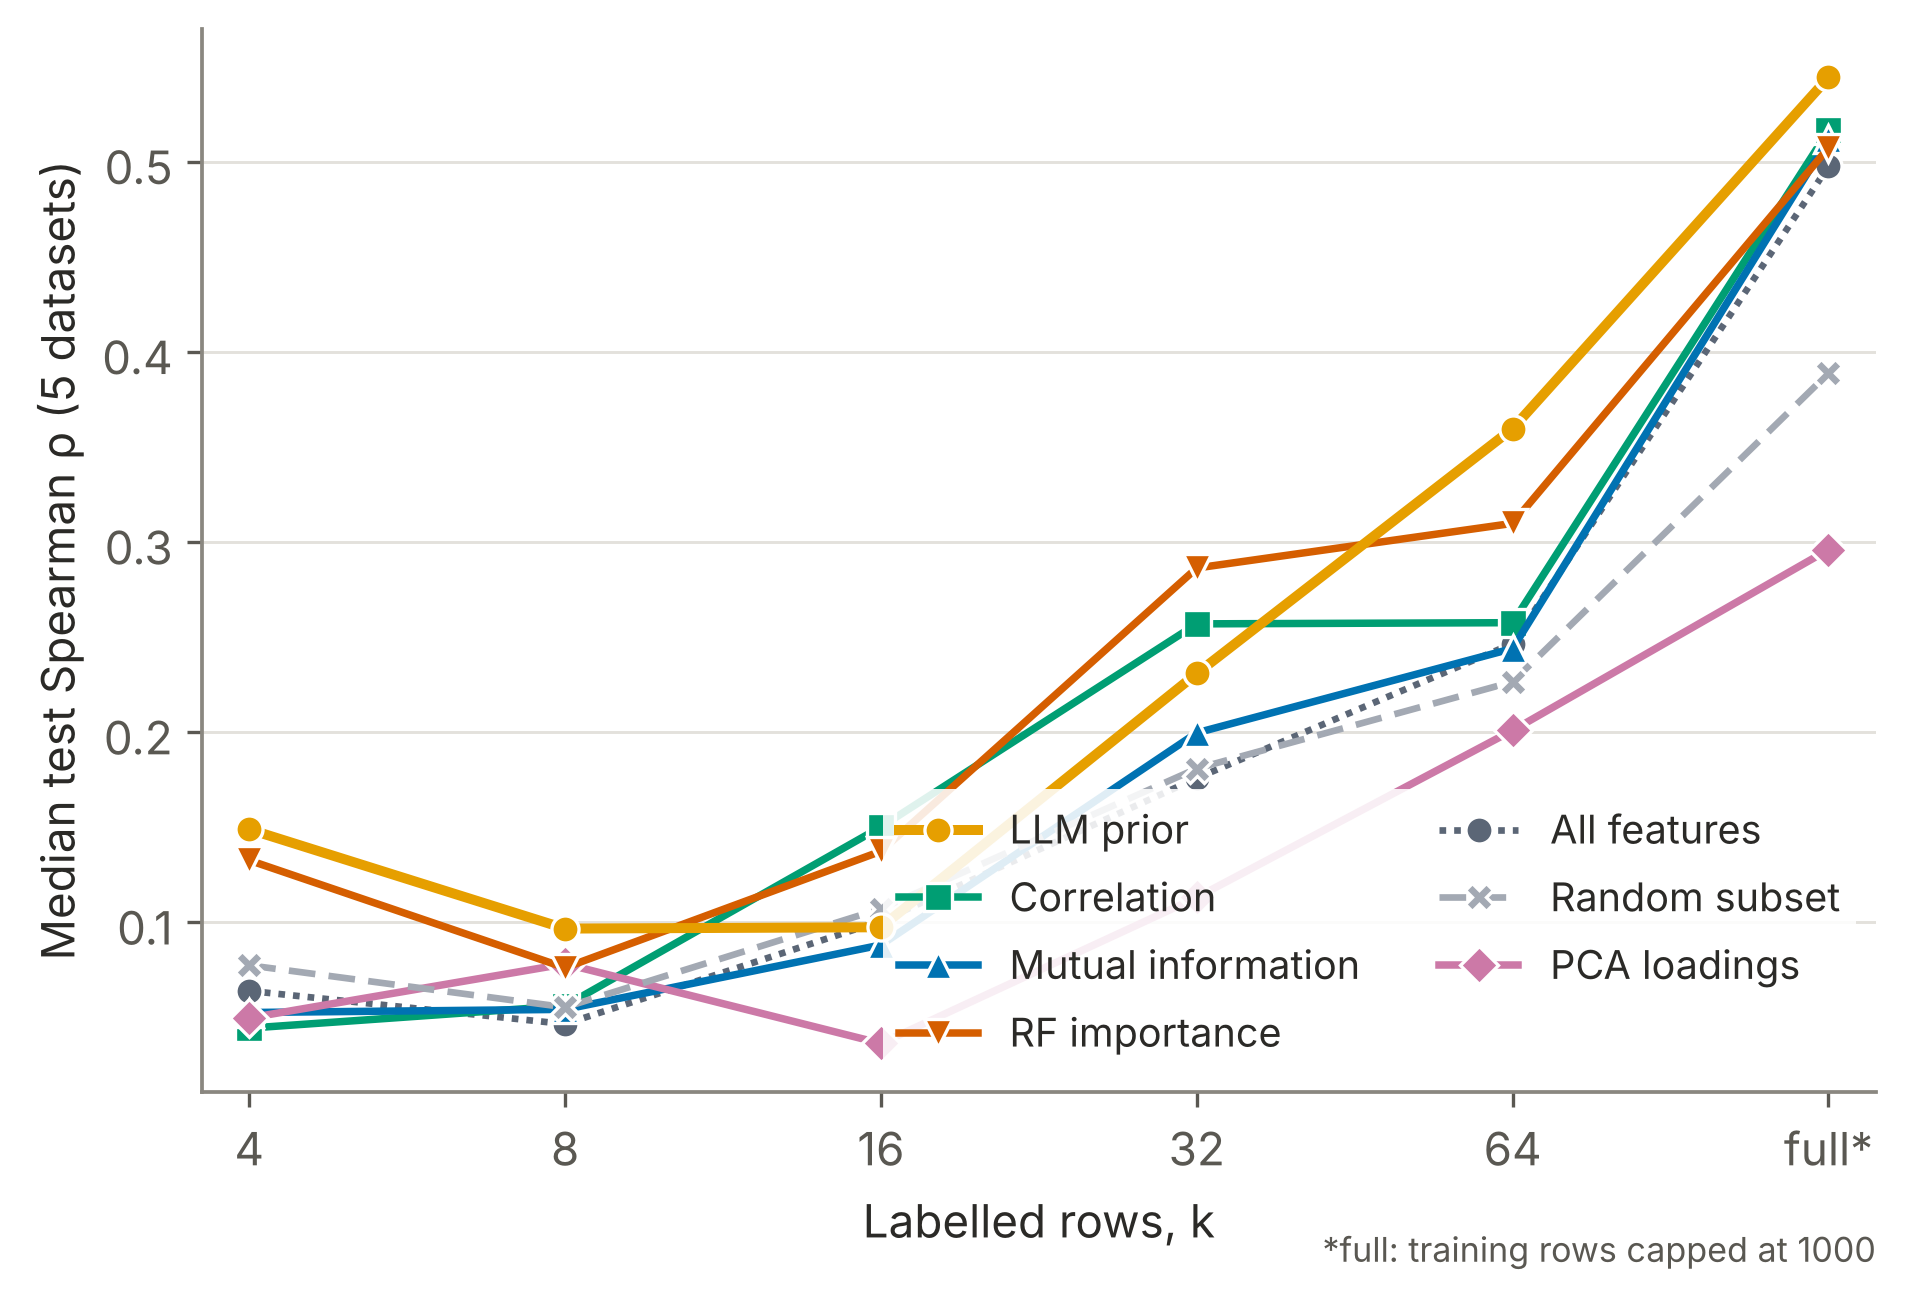

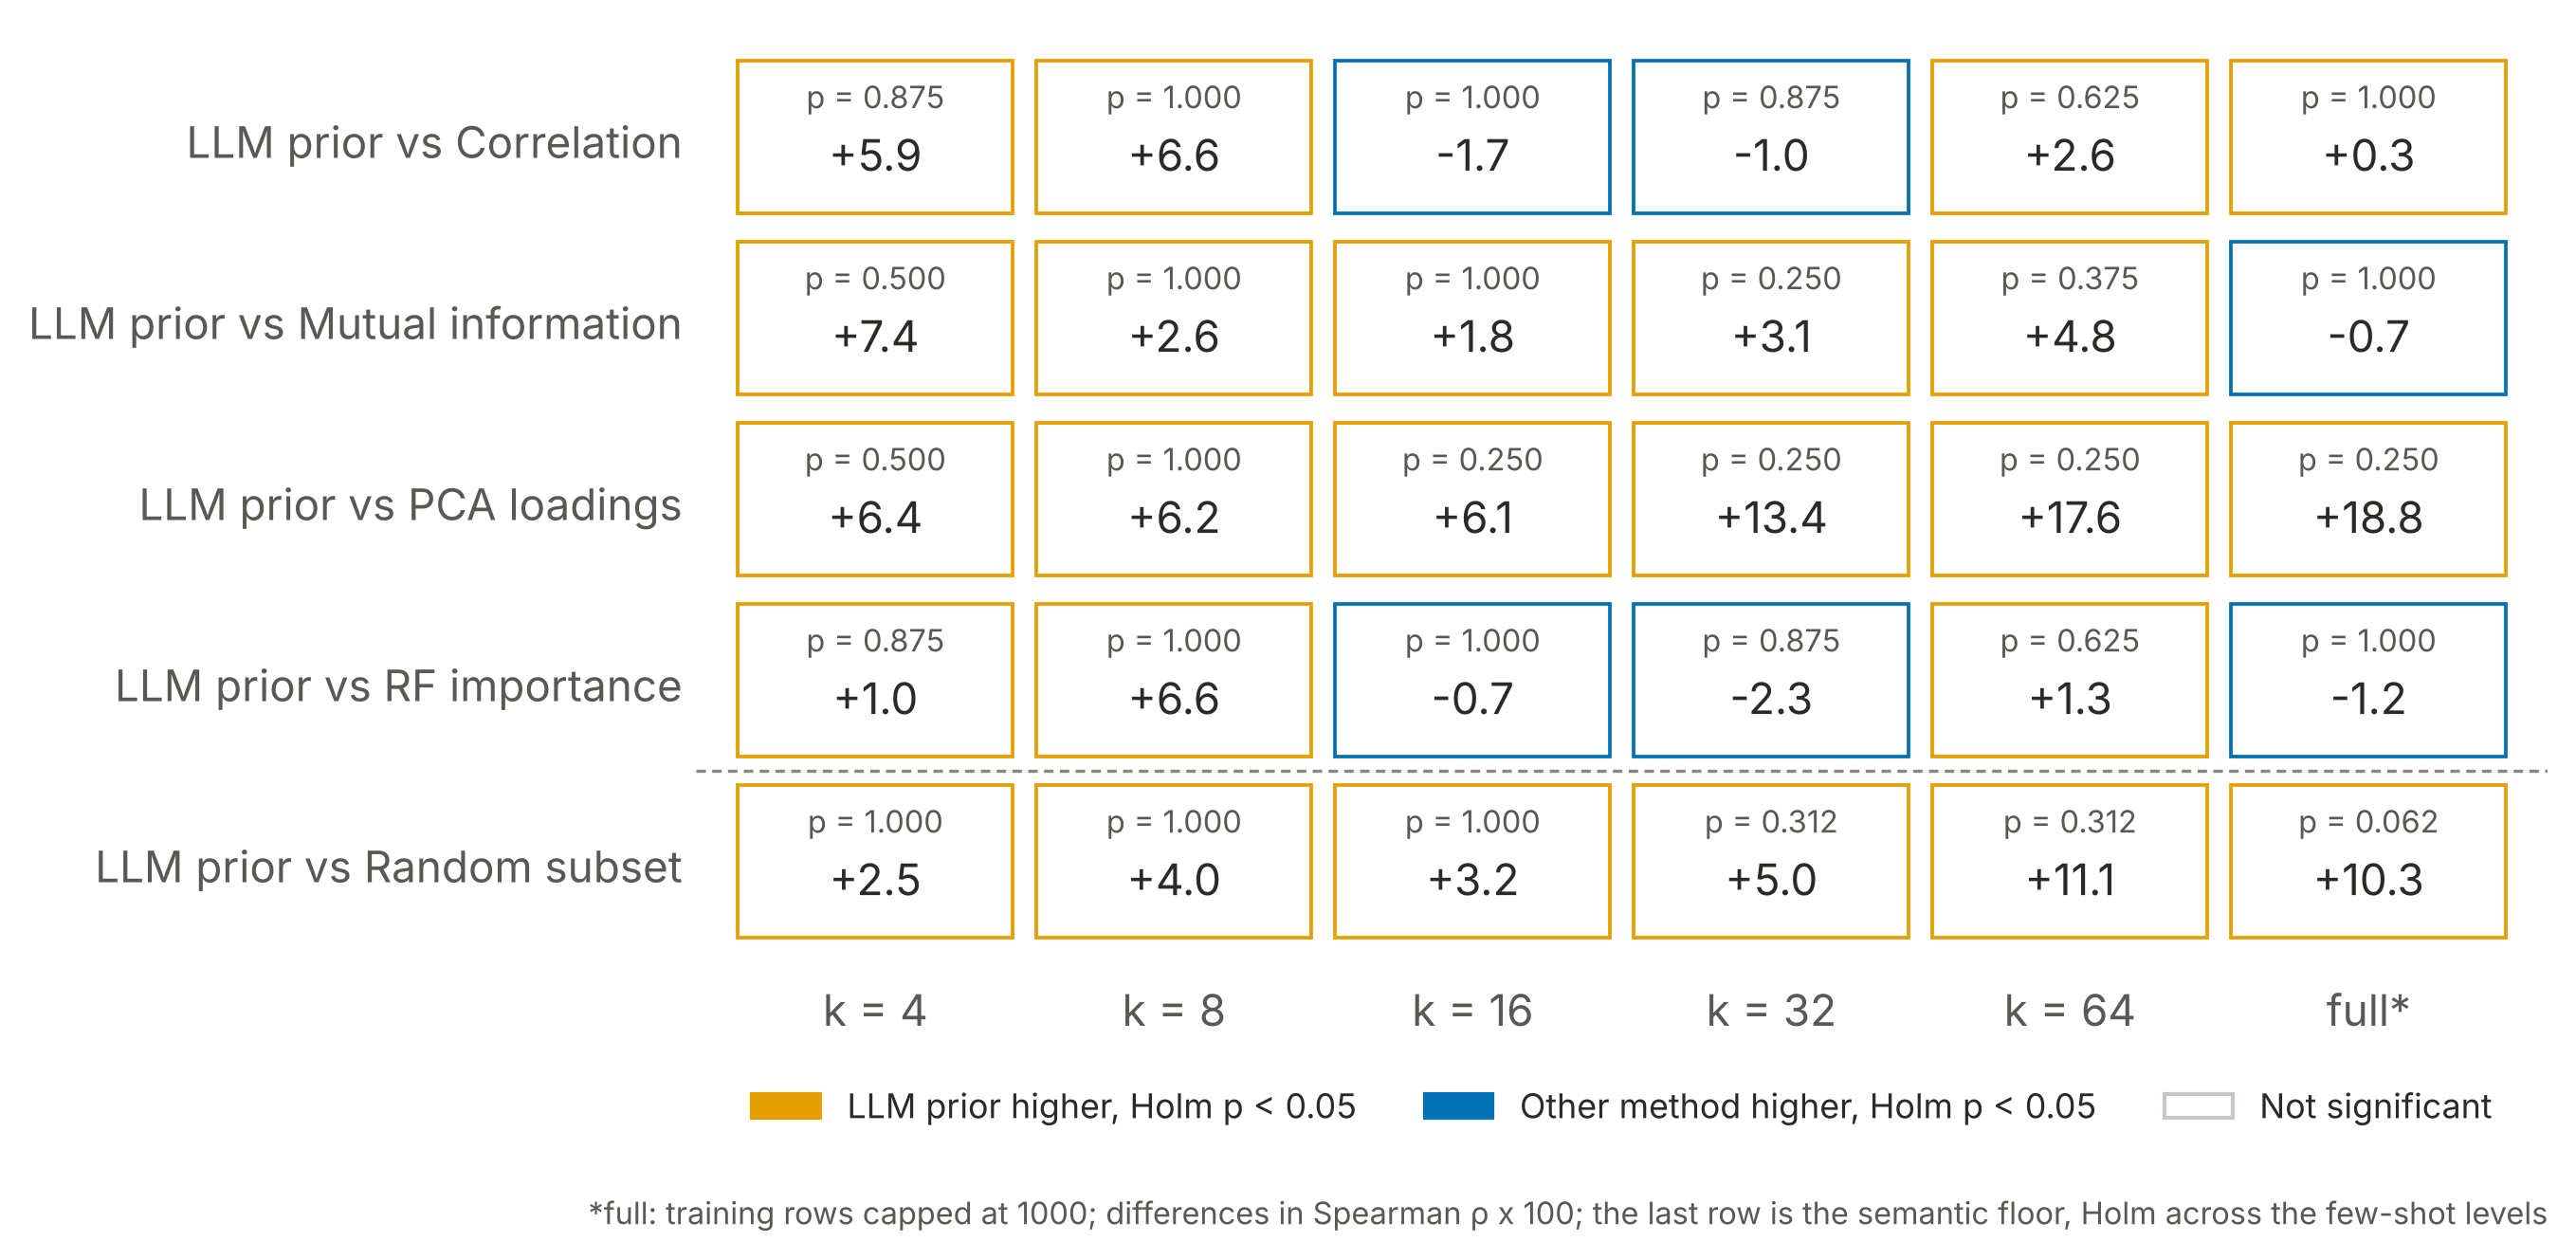

In [17]:
if (A / "regression" / "pooled_summary.csv").exists():
    display(pooled_table("regression"))
    if (A / "regression" / "pooled_summary_secondary.csv").exists():
        display(Markdown("Secondary metric, calibrated R² (x 100):"))
        sec = pd.read_csv(A / "regression" / "pooled_summary_secondary.csv", dtype={"shot": str})
        shots = [s for s in config.ALL_SHOTS if s in set(sec.shot)]
        t = (sec.pivot(index="control", columns="shot", values="pooled_median").reindex(METHODS)[shots] * 100).round(1)
        t.index = t.index.map(NAMES); t.index.name = "Method"
        display(t)
    reg = pd.read_csv(A / "regression" / "confirmatory_wilcoxon.csv", dtype={"shot": str})
    reg["contrast"] = reg.contrast.map(lambda s: "LLM prior vs " + NAMES[s.split(" vs ")[1]])
    display(reg[["shot", "contrast", "n_datasets", "median_diff_pts", "wilcoxon_p", "cliffs_delta", "magnitude"]].round(3))
    display(Image(str(F / "regression" / "fig_pooled_score_vs_shot_all.png"), width=760))
    display(Image(str(F / "regression" / "fig_significance_confirmatory.png"), width=820))

## Cross-task ranks and the point of contact with Memar et al. (2026)

Within-dataset ranks pool across both task types (exploratory). The contact
table places our per-dataset means at k = 64 and at the capped full level
beside the values Memar et al. report on the datasets both studies use;
the protocols differ (XGBoost on a 60% training split there, GE on k rows
here), so it locates the studies, it does not compare methods.

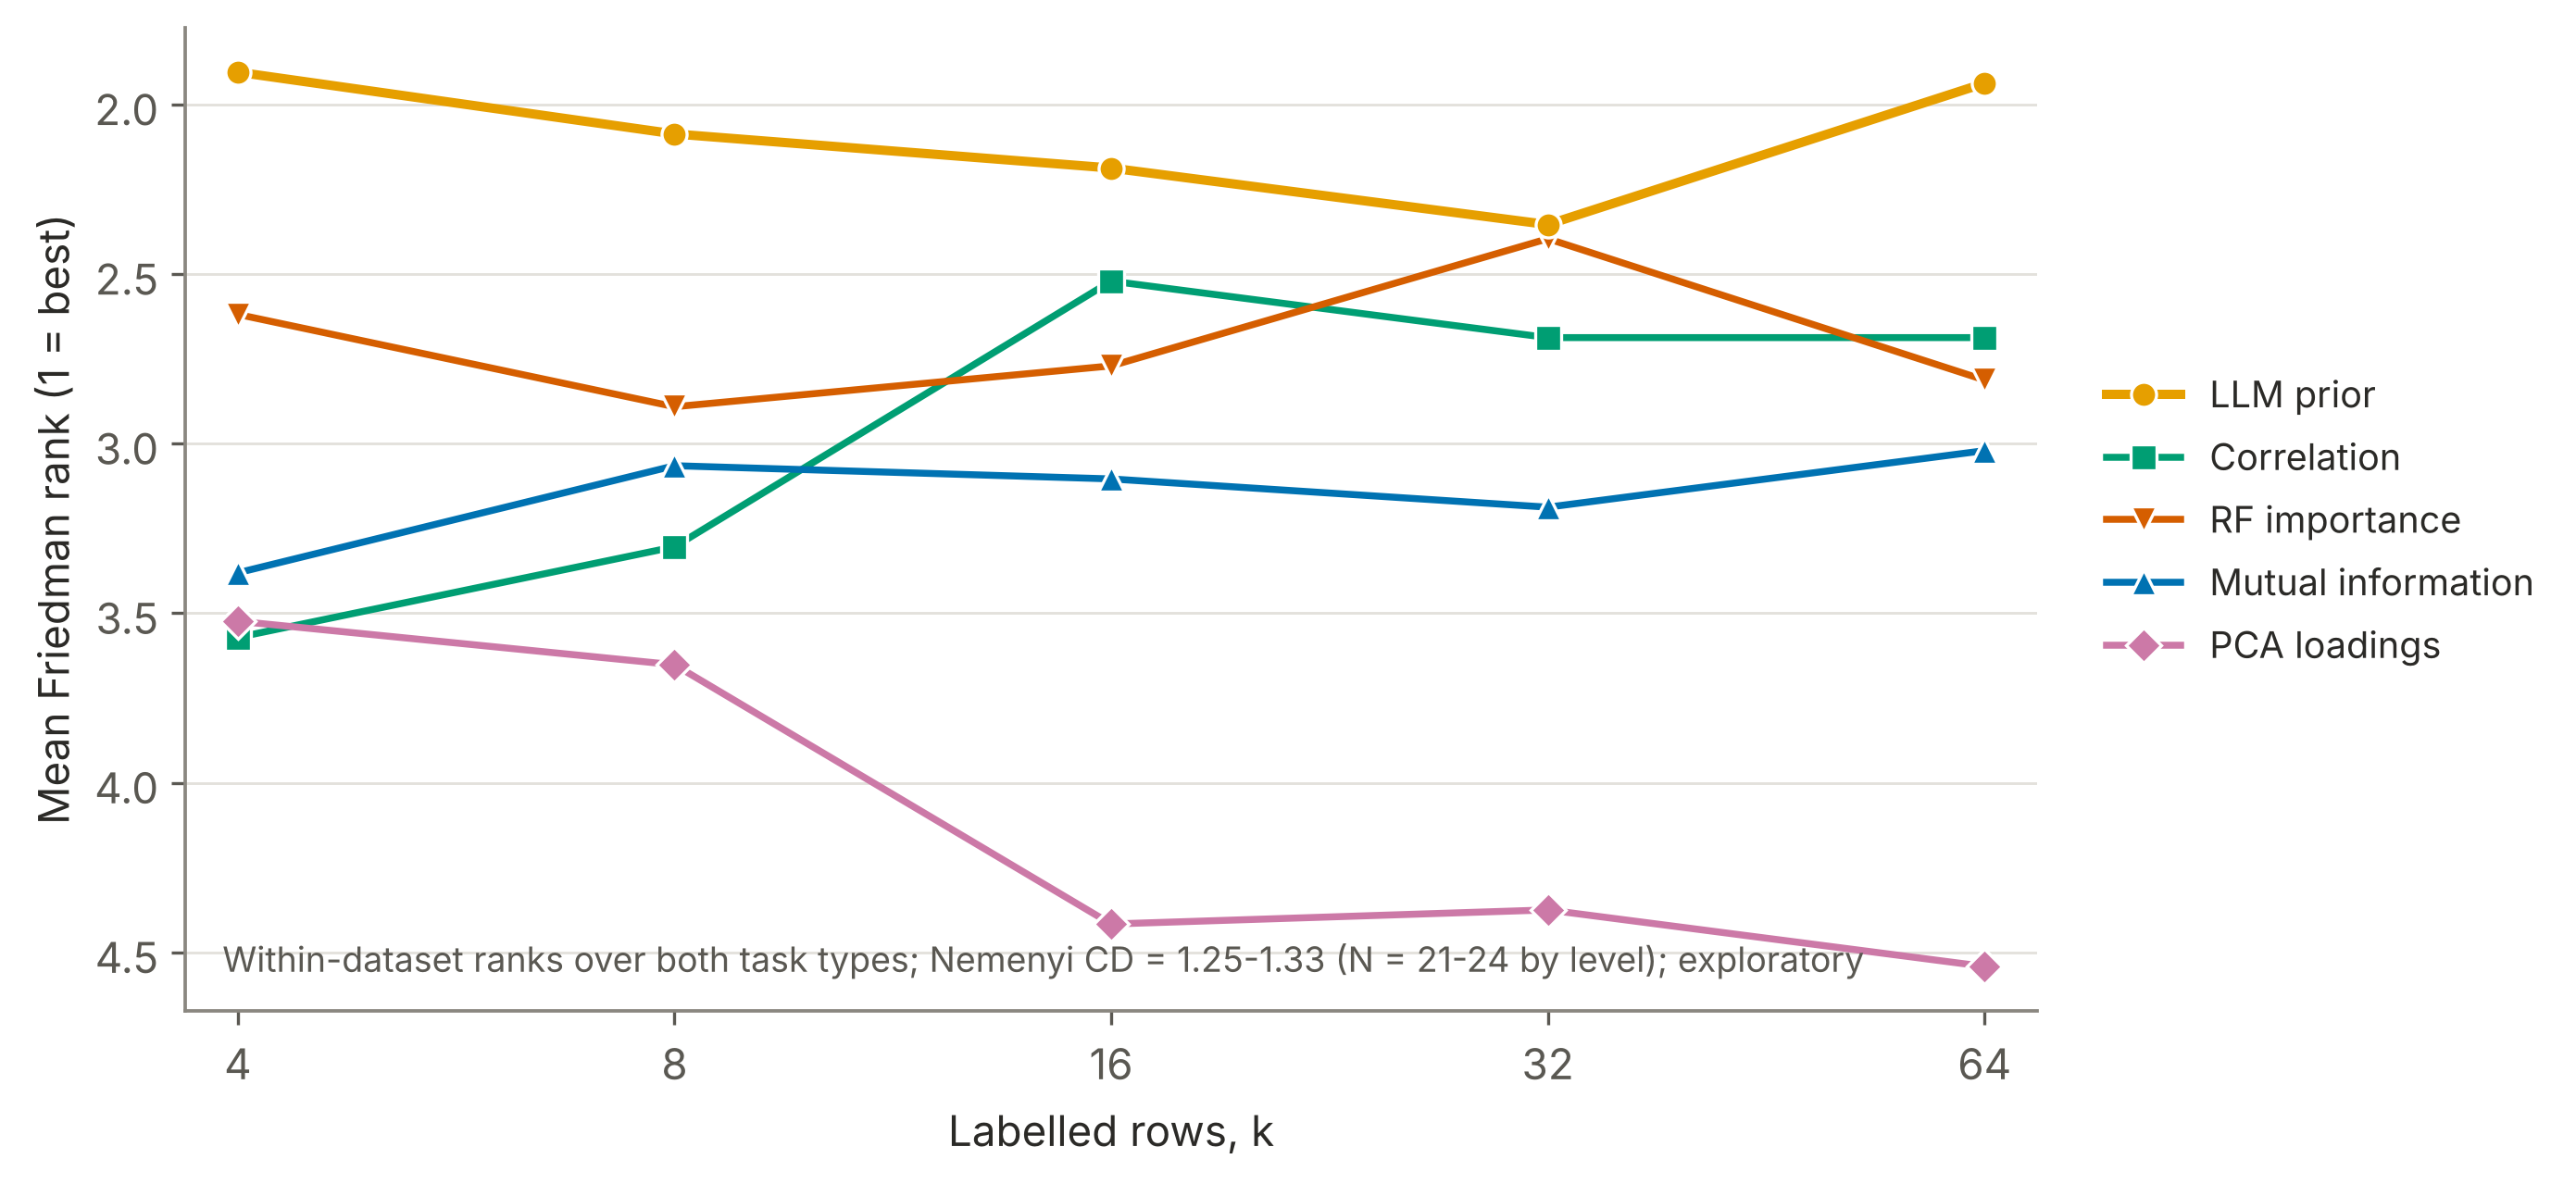

,dataset,our_level,ours_none,ours_best_classical,ours_llm,memar_No Selection,memar_XGB Importance,memar_Zero-shot Llama-70B,memar_RL-GRPO v1
0,adult,64,0.800,0.792,0.816,0.922,0.912,0.914,0.852
1,adult,full,0.864,0.883,0.874,0.922,0.912,0.914,0.852
2,sonar,64,0.755,0.760,0.716,0.912,0.887,0.864,0.726
3,sonar,full,0.777,0.768,0.768,0.912,0.887,0.864,0.726
4,student_dropout,64,0.745,0.779,0.781,0.894,0.891,0.856,0.819
5,student_dropout,full,0.841,0.850,0.853,0.894,0.891,0.856,0.819
6,ames_housing,64,0.555,0.727,0.680,0.915,0.918,0.903,0.873
7,ames_housing,full,0.749,0.804,0.805,0.915,0.918,0.903,0.873
8,parkinsons,64,0.009,0.034,-0.002,0.884,0.890,0.886,0.888
9,parkinsons,full,0.119,0.154,0.126,0.884,0.890,0.886,0.888


In [18]:
display(Image(str(F / "fig_cross_task_mean_rank_vs_shot.png"), width=820))
if (A / "contact_memar_table1.csv").exists():
    ct = pd.read_csv(A / "contact_memar_table1.csv")
    cols = ["dataset", "our_level", "ours_none", "ours_best_classical", "ours_llm",
            "memar_No Selection", "memar_XGB Importance", "memar_Zero-shot Llama-70B", "memar_RL-GRPO v1"]
    display(ct[[c for c in cols if c in ct.columns]].round(3))

## Computational cost and stability

Wall-clock seconds per GE cell, paired within the (dataset, shot, draw)
cell against the all-features run; and the mean pairwise Jaccard
similarity of the subsets each method selected across draws (the cached
prior is a fixed subset, so its stability is one by construction).

,contrast,n_datasets,median_ratio,holm_p,cliffs_delta,magnitude
36,corr vs none,24,0.995,1.000,0.024,negligible
37,mi vs none,24,1.062,1.000,0.160,small
38,pca vs none,24,1.024,1.000,0.104,negligible
39,rf vs none,24,1.000,1.000,0.097,negligible
40,llm vs none,24,1.014,1.000,-0.010,negligible
41,random vs none,24,1.026,0.017,0.076,negligible


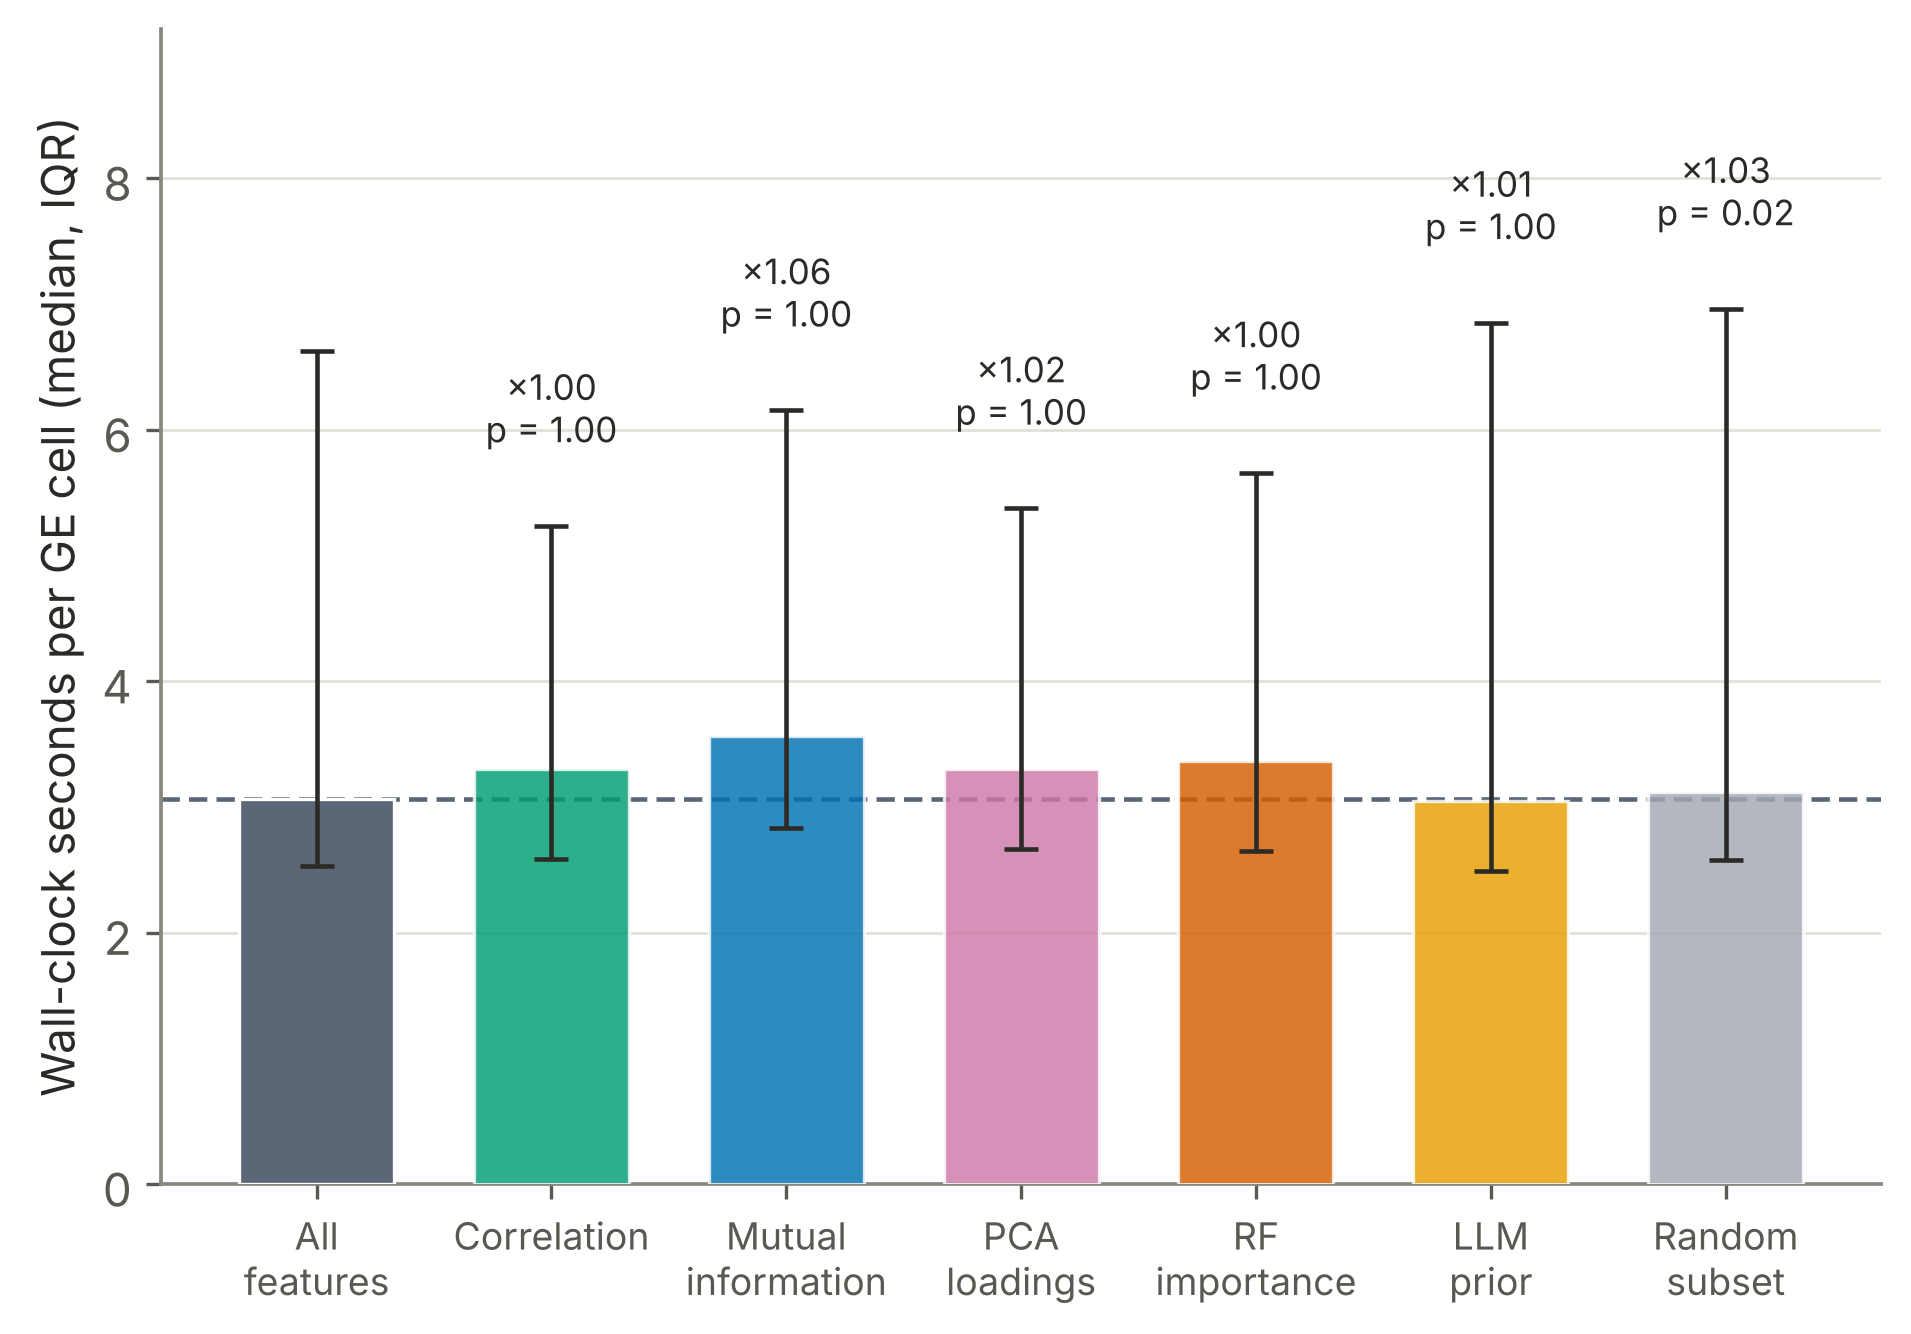

shot,4,8,16,32,64,full
Method,,,,,,
Correlation,0.37,0.35,0.38,0.45,0.54,0.83
Mutual information,0.46,0.43,0.42,0.45,0.49,0.67
PCA loadings,0.34,0.31,0.33,0.35,0.37,0.62
RF importance,0.45,0.42,0.44,0.51,0.60,0.84
LLM prior,1.00,1.00,1.00,1.00,1.00,1.00
Random subset,0.26,0.25,0.25,0.25,0.25,0.25


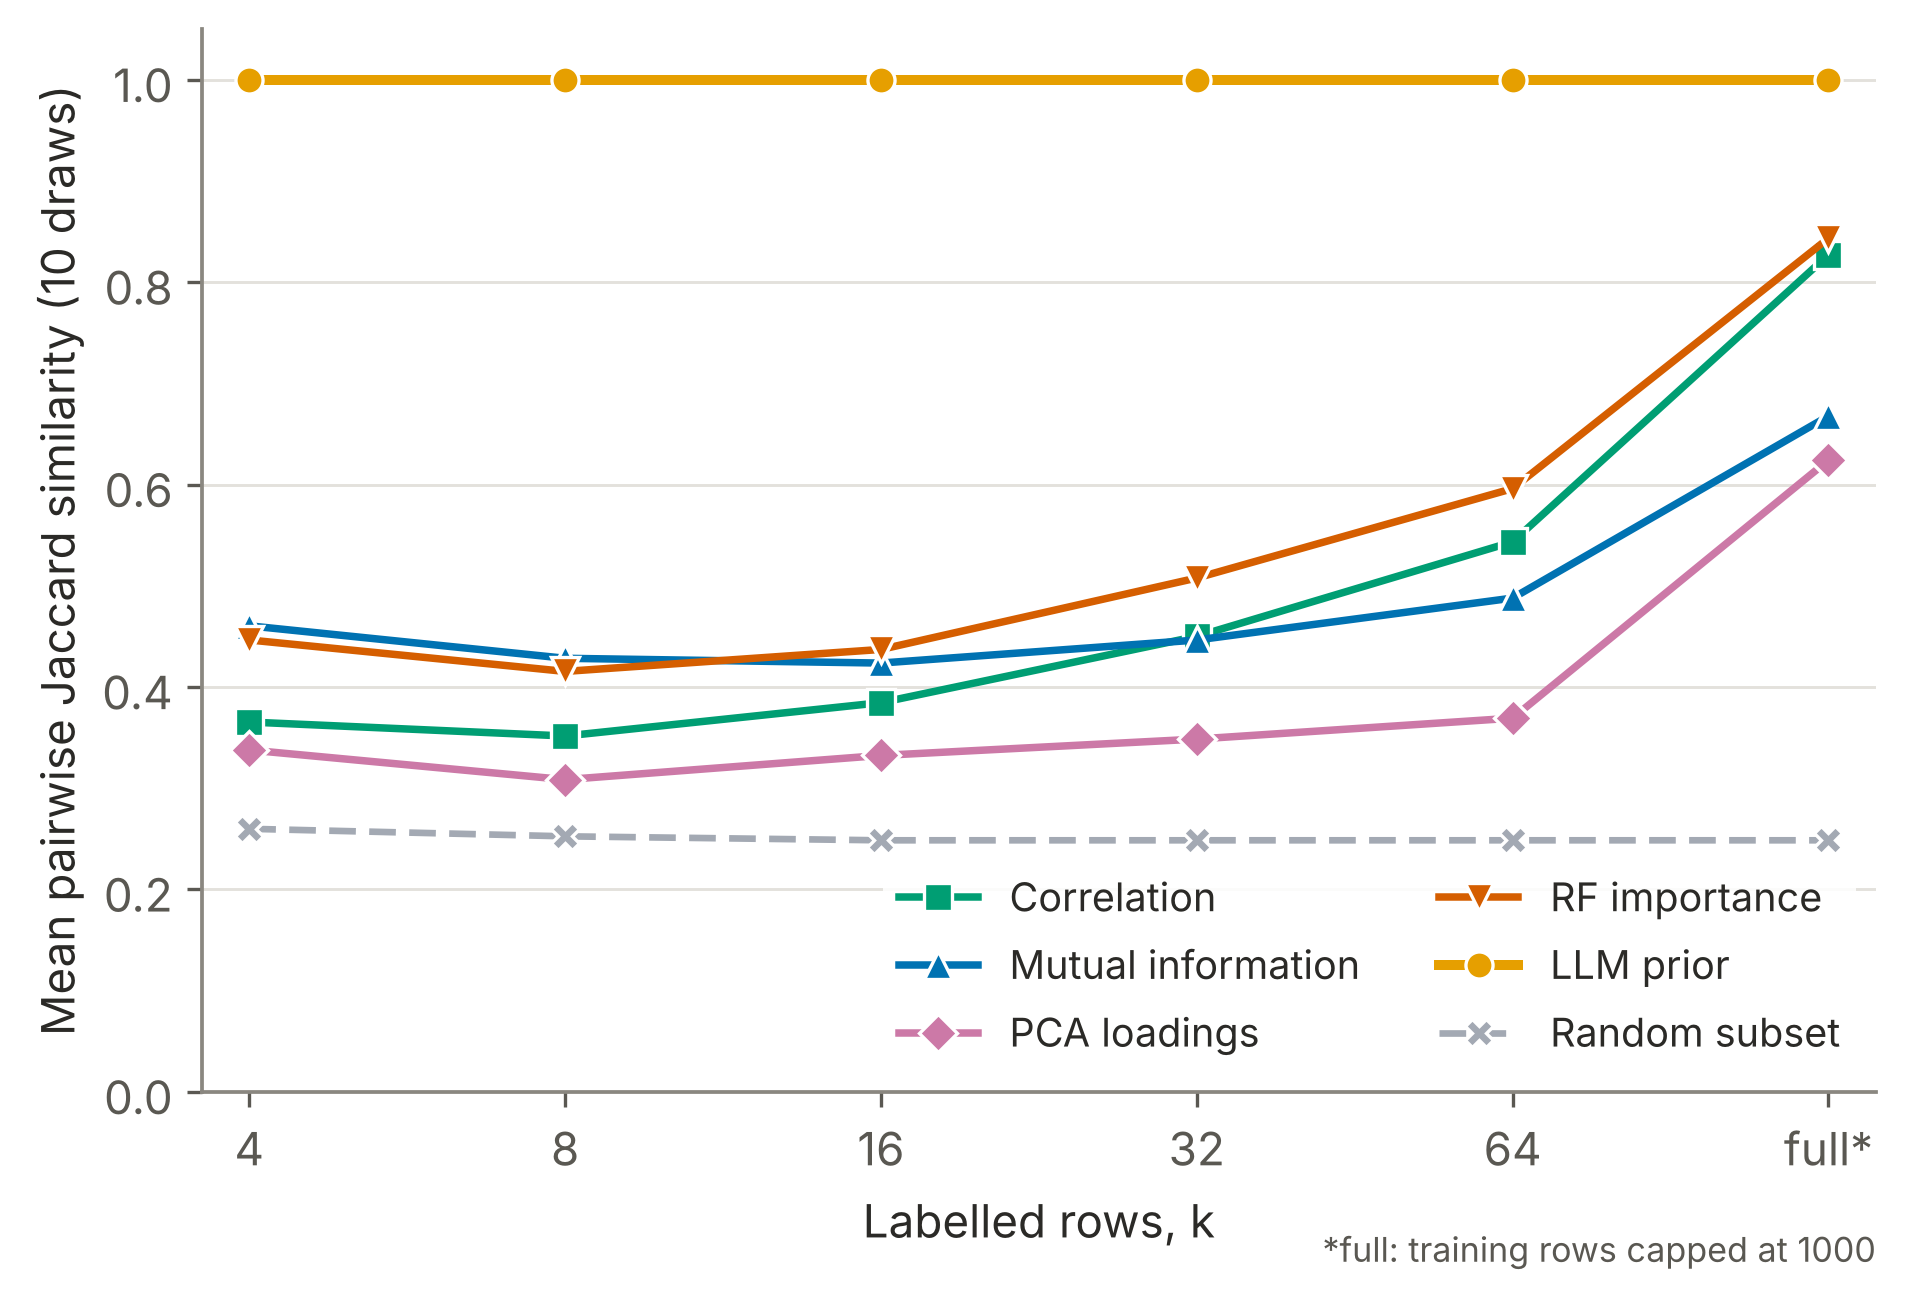

In [19]:
tc = pd.read_csv(A / "compute_time_contrasts.csv", dtype={"shot": str})
display(tc[tc.shot == "all"][["contrast", "n_datasets", "median_ratio", "holm_p", "cliffs_delta", "magnitude"]].round(3))
display(Image(str(F / "fig_compute_time.png"), width=820))
stab = pd.read_csv(A / "classification" / "stability_pooled.csv", dtype={"shot": str})
st = stab.pivot(index="control", columns="shot", values="stability").reindex(
    [m for m in METHODS if m != "none"])[[s for s in config.ALL_SHOTS if s in set(stab.shot)]].round(2)
st.index = st.index.map(NAMES); st.index.name = "Method"
display(st)
display(Image(str(F / "classification" / "fig_stability_vs_shot.png"), width=760))

## Both designs side by side

Once both campaigns have been analysed (run the notebook once per `DESIGN`),
`compare_designs.py` lays their tables side by side under
`results/comparison/`.

In [20]:
!"{sys.executable}" compare_designs.py
from IPython.display import Markdown
cmp_path = ROOT / "results" / "comparison" / "comparison.md"
if cmp_path.exists():
    display(Markdown(cmp_path.read_text(encoding="utf-8")))

-> /home/claude/ge_selector_comparison/results/comparison


# The two designs side by side

Full-information: the data-driven selectors score the whole training partition of the split. Matched: they score only the k labelled rows the learner sees. The LLM prior, the random subset and the all-features baseline are identical in both (verified cell for cell by check_reference.py). Numbers are read from each campaign's analysis tables.

## classification (19 datasets, test ROC-AUC x 100, role: primary)

Pooled medians (full = full-information, matc = matched):

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       57.3 |       60.9 |        66.9 |        74.4 |        80.2 |        86.9 |       57.3 |       60.9 |        66.9 |        74.4 |        80.2 |        86.9 |
| Correlation        |       62.4 |       68.0 |        73.2 |        77.2 |        82.8 |        88.3 |       58.0 |       61.2 |        70.0 |        73.5 |        79.5 |        87.3 |
| Mutual information |       64.2 |       68.1 |        72.0 |        76.8 |        82.9 |        88.3 |       60.3 |       62.4 |        67.9 |        74.0 |        81.4 |        87.3 |
| PCA loadings       |       57.8 |       60.1 |        64.1 |        71.4 |        75.9 |        82.7 |       59.4 |       58.9 |        64.0 |        71.4 |        74.7 |        80.3 |
| RF importance      |       63.8 |       66.4 |        71.3 |        75.6 |        82.8 |        88.3 |       58.0 |       63.3 |        70.0 |        74.4 |        79.2 |        88.3 |
| LLM prior          |       63.0 |       65.0 |        70.6 |        75.1 |        81.6 |        87.4 |       63.0 |       65.0 |        70.6 |        75.1 |        81.6 |        87.4 |
| Random subset      |       58.6 |       62.5 |        65.7 |        70.5 |        73.3 |        81.4 |       58.6 |       62.5 |        65.7 |        70.5 |        73.3 |        81.4 |

Confirmatory contrasts, LLM prior against each selector (median difference, Holm p, Cliff's delta, significant):

| shot   | contrast    |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs corr |                            16 |                             -0.709 |                     0.747 |                          -0.074 | False                             |                   16 |                     3.069 |            0.115 |                  0.180 | False                    |
| 4      | llm vs mi   |                            16 |                              0.052 |                     0.991 |                          -0.074 | False                             |                   16 |                     3.339 |            0.064 |                  0.211 | False                    |
| 4      | llm vs pca  |                            16 |                              2.330 |                     0.031 |                           0.266 | True                              |                   16 |                     2.340 |            0.052 |                  0.211 | False                    |
| 4      | llm vs rf   |                            16 |                              0.044 |                     0.991 |                          -0.066 | False                             |                   16 |                     1.756 |            0.211 |                  0.094 | False                    |
| 8      | llm vs corr |                            18 |                             -1.233 |                     0.060 |                          -0.148 | False                             |                   18 |                     3.220 |            0.020 |                  0.216 | True                     |
| 8      | llm vs mi   |                            18 |                             -0.310 |                     1.000 |                          -0.059 | False                             |                   18 |                     2.881 |            0.020 |                  0.179 | True                     |
| 8      | llm vs pca  |                            18 |                              4.987 |                     0.001 |                           0.333 | True                              |                   18 |                     5.925 |            0.001 |                  0.340 | True                     |
| 8      | llm vs rf   |                            18 |                              0.590 |                     1.000 |                          -0.040 | False                             |                   18 |                     3.567 |            0.020 |                  0.148 | True                     |
| 16     | llm vs corr |                            19 |                             -0.892 |                     0.419 |                          -0.069 | False                             |                   19 |                     1.507 |            0.170 |                  0.089 | False                    |
| 16     | llm vs mi   |                            19 |                             -0.539 |                     0.712 |                          -0.053 | False                             |                   19 |                     3.432 |            0.022 |                  0.177 | True                     |
| 16     | llm vs pca  |                            19 |                              5.687 |                     0.020 |                           0.305 | True                              |                   19 |                     6.085 |            0.005 |                  0.335 | True                     |
| 16     | llm vs rf   |                            19 |                              0.045 |                     0.712 |                           0.025 | False                             |                   19 |                     1.787 |            0.077 |                  0.111 | False                    |
| 32     | llm vs corr |                            19 |                             -0.358 |                     0.116 |                          -0.066 | False                             |                   19 |                     0.910 |            0.340 |                  0.089 | False                    |
| 32     | llm vs mi   |                            19 |                             -0.202 |                     1.000 |                          -0.022 | False                             |                   19 |                     0.904 |            0.233 |                  0.094 | False                    |
| 32     | llm vs pca  |                            19 |                              2.414 |                     0.015 |                           0.244 | True                              |                   19 |                     4.710 |            0.001 |                  0.269 | True                     |
| 32     | llm vs rf   |                            19 |                              0.000 |                     1.000 |                           0.019 | False                             |                   19 |                     0.215 |            0.340 |                  0.089 | False                    |
| 64     | llm vs corr |                            19 |                              0.000 |                     1.000 |                          -0.006 | False                             |                   19 |                     0.612 |            0.171 |                  0.050 | False                    |
| 64     | llm vs mi   |                            19 |                             -0.191 |                     1.000 |                          -0.017 | False                             |                   19 |                     0.470 |            0.171 |                  0.078 | False                    |
| 64     | llm vs pca  |                            19 |                              4.834 |                     0.002 |                           0.199 | True                              |                   19 |                     3.495 |            0.000 |                  0.191 | True                     |
| 64     | llm vs rf   |                            19 |                              0.000 |                     1.000 |                           0.008 | False                             |                   19 |                     0.954 |            0.029 |                  0.050 | True                     |
| full   | llm vs corr |                            19 |                              0.000 |                     1.000 |                           0.000 | False                             |                   19 |                     0.058 |            0.938 |                  0.017 | False                    |
| full   | llm vs mi   |                            19 |                              0.112 |                     1.000 |                           0.044 | False                             |                   19 |                     0.192 |            0.597 |                  0.066 | False                    |
| full   | llm vs pca  |                            19 |                              2.600 |                     0.020 |                           0.177 | True                              |                   19 |                     2.600 |            0.015 |                  0.166 | True                     |
| full   | llm vs rf   |                            19 |                              0.000 |                     1.000 |                           0.003 | False                             |                   19 |                     0.000 |            0.938 |                 -0.014 | False                    |

Semantic floor, LLM prior against the random subset:

| shot   | contrast      |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:--------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs random |                            16 |                              4.424 |                     0.000 |                           0.312 | True                              |                   16 |                     4.424 |            0.000 |                  0.312 | True                     |
| 8      | llm vs random |                            18 |                              4.598 |                     0.001 |                           0.204 | True                              |                   18 |                     4.598 |            0.001 |                  0.204 | True                     |
| 16     | llm vs random |                            19 |                              3.976 |                     0.008 |                           0.263 | True                              |                   19 |                     3.976 |            0.008 |                  0.263 | True                     |
| 32     | llm vs random |                            19 |                              3.461 |                     0.000 |                           0.235 | True                              |                   19 |                     3.461 |            0.000 |                  0.235 | True                     |
| 64     | llm vs random |                            19 |                              4.519 |                     0.000 |                           0.252 | True                              |                   19 |                     4.519 |            0.000 |                  0.252 | True                     |
| full   | llm vs random |                            19 |                              3.446 |                     0.000 |                           0.235 | True                              |                   19 |                     3.446 |            0.000 |                  0.235 | True                     |

Friedman mean ranks over the five selection methods (1 = best):

|   shot |   full_information:n_datasets |   full_information:friedman_p |   full_information:rank_corr |   full_information:rank_mi |   full_information:rank_pca |   full_information:rank_rf |   full_information:rank_llm |   matched:n_datasets |   matched:friedman_p |   matched:rank_corr |   matched:rank_mi |   matched:rank_pca |   matched:rank_rf |   matched:rank_llm |
|-------:|------------------------------:|------------------------------:|-----------------------------:|---------------------------:|----------------------------:|---------------------------:|----------------------------:|---------------------:|---------------------:|--------------------:|------------------:|-------------------:|------------------:|-------------------:|
|      4 |                            16 |                         0.024 |                        2.375 |                      2.688 |                       4.094 |                      2.938 |                       2.906 |                   16 |                0.013 |               3.562 |             3.375 |              3.500 |             2.625 |              1.938 |
|      8 |                            18 |                         0.000 |                        1.944 |                      2.583 |                       4.500 |                      3.139 |                       2.833 |                   18 |                0.023 |               3.222 |             3.028 |              3.833 |             2.806 |              2.111 |
|     16 |                            19 |                         0.000 |                        2.105 |                      2.316 |                       4.368 |                      3.132 |                       3.079 |                   19 |                0.000 |               2.500 |             3.184 |              4.263 |             2.974 |              2.079 |
|     32 |                            19 |                         0.000 |                        1.895 |                      2.947 |                       4.316 |                      2.921 |                       2.921 |                   19 |                0.001 |               2.868 |             3.026 |              4.263 |             2.500 |              2.342 |
|     64 |                            19 |                         0.000 |                        2.658 |                      2.289 |                       4.421 |                      2.816 |                       2.816 |                   19 |                0.000 |               2.605 |             2.974 |              4.421 |             3.026 |              1.974 |

Subset stability, mean pairwise Jaccard across draws:

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Correlation        |       0.89 |       0.90 |        0.90 |        0.90 |        0.90 |        0.90 |       0.37 |       0.35 |        0.38 |        0.45 |        0.54 |        0.83 |
| Mutual information |       0.72 |       0.73 |        0.74 |        0.74 |        0.74 |        0.74 |       0.46 |       0.43 |        0.42 |        0.45 |        0.49 |        0.67 |
| PCA loadings       |       0.66 |       0.67 |        0.67 |        0.67 |        0.67 |        0.67 |       0.34 |       0.31 |        0.33 |        0.35 |        0.37 |        0.62 |
| RF importance      |       0.89 |       0.88 |        0.88 |        0.88 |        0.88 |        0.88 |       0.45 |       0.42 |        0.44 |        0.51 |        0.60 |        0.84 |
| LLM prior          |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Random subset      |       0.26 |       0.25 |        0.25 |        0.25 |        0.25 |        0.25 |       0.26 |       0.25 |        0.25 |        0.25 |        0.25 |        0.25 |

## regression (5 datasets, test Spearman ρ x 100, role: descriptive)

Pooled medians (full = full-information, matc = matched):

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |        6.4 |        4.6 |        10.1 |        17.6 |        24.7 |        49.8 |        6.4 |        4.6 |        10.1 |        17.6 |        24.7 |        49.8 |
| Correlation        |       14.5 |       11.1 |        14.5 |        24.5 |        33.8 |        51.6 |        4.4 |        5.6 |        15.0 |        25.7 |        25.8 |        51.6 |
| Mutual information |        6.9 |        5.6 |        12.7 |        19.4 |        30.3 |        48.7 |        5.3 |        5.4 |         8.8 |        20.0 |        24.4 |        51.2 |
| PCA loadings       |        3.7 |        5.9 |         4.8 |         7.9 |         9.3 |        29.6 |        5.0 |        7.8 |         3.6 |        11.3 |        20.1 |        29.6 |
| RF importance      |        7.7 |       10.4 |        16.9 |        28.2 |        32.5 |        50.7 |       13.3 |        7.6 |        13.7 |        28.6 |        31.0 |        50.7 |
| LLM prior          |       14.9 |        9.7 |         9.7 |        23.1 |        36.0 |        54.4 |       14.9 |        9.7 |         9.7 |        23.1 |        36.0 |        54.4 |
| Random subset      |        7.7 |        5.5 |        10.7 |        18.1 |        22.6 |        38.9 |        7.7 |        5.5 |        10.7 |        18.1 |        22.6 |        38.9 |

Confirmatory contrasts, LLM prior against each selector (median difference, Holm p, Cliff's delta, significant):

| shot   | contrast    |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs corr |                             5 |                              1.576 |                     1.000 |                           0.120 | False                             |                    5 |                     5.852 |            0.875 |                  0.360 | False                    |
| 4      | llm vs mi   |                             5 |                              0.959 |                     1.000 |                           0.120 | False                             |                    5 |                     7.393 |            0.500 |                  0.280 | False                    |
| 4      | llm vs pca  |                             5 |                             12.761 |                     0.250 |                           0.520 | False                             |                    5 |                     6.351 |            0.500 |                  0.440 | False                    |
| 4      | llm vs rf   |                             5 |                              5.737 |                     1.000 |                           0.360 | False                             |                    5 |                     1.010 |            0.875 |                  0.280 | False                    |
| 8      | llm vs corr |                             5 |                              0.300 |                     1.000 |                           0.040 | False                             |                    5 |                     6.575 |            1.000 |                  0.280 | False                    |
| 8      | llm vs mi   |                             5 |                             -0.071 |                     1.000 |                           0.040 | False                             |                    5 |                     2.630 |            1.000 |                  0.200 | False                    |
| 8      | llm vs pca  |                             5 |                              8.388 |                     1.000 |                           0.280 | False                             |                    5 |                     6.242 |            1.000 |                  0.120 | False                    |
| 8      | llm vs rf   |                             5 |                              2.159 |                     1.000 |                          -0.120 | False                             |                    5 |                     6.570 |            1.000 |                  0.200 | False                    |
| 16     | llm vs corr |                             5 |                             -3.681 |                     0.500 |                          -0.200 | False                             |                    5 |                    -1.711 |            1.000 |                 -0.200 | False                    |
| 16     | llm vs mi   |                             5 |                              0.158 |                     1.000 |                           0.040 | False                             |                    5 |                     1.816 |            1.000 |                 -0.040 | False                    |
| 16     | llm vs pca  |                             5 |                              4.930 |                     0.562 |                           0.120 | False                             |                    5 |                     6.110 |            0.250 |                  0.440 | False                    |
| 16     | llm vs rf   |                             5 |                             -3.787 |                     1.000 |                          -0.120 | False                             |                    5 |                    -0.661 |            1.000 |                 -0.280 | False                    |
| 32     | llm vs corr |                             5 |                             -0.336 |                     1.000 |                          -0.120 | False                             |                    5 |                    -0.996 |            0.875 |                 -0.120 | False                    |
| 32     | llm vs mi   |                             5 |                             -1.590 |                     1.000 |                           0.040 | False                             |                    5 |                     3.122 |            0.250 |                  0.280 | False                    |
| 32     | llm vs pca  |                             5 |                             16.966 |                     0.250 |                           0.600 | False                             |                    5 |                    13.364 |            0.250 |                  0.600 | False                    |
| 32     | llm vs rf   |                             5 |                             -1.608 |                     1.000 |                          -0.040 | False                             |                    5 |                    -2.330 |            0.875 |                 -0.040 | False                    |
| 64     | llm vs corr |                             5 |                              0.970 |                     1.000 |                           0.040 | False                             |                    5 |                     2.593 |            0.625 |                  0.200 | False                    |
| 64     | llm vs mi   |                             5 |                              0.904 |                     1.000 |                           0.200 | False                             |                    5 |                     4.815 |            0.375 |                  0.280 | False                    |
| 64     | llm vs pca  |                             5 |                             19.581 |                     0.250 |                           0.520 | False                             |                    5 |                    17.622 |            0.250 |                  0.520 | False                    |
| 64     | llm vs rf   |                             5 |                              0.477 |                     1.000 |                           0.040 | False                             |                    5 |                     1.342 |            0.625 |                  0.040 | False                    |
| full   | llm vs corr |                             5 |                              0.048 |                     1.000 |                           0.120 | False                             |                    5 |                     0.330 |            1.000 |                  0.200 | False                    |
| full   | llm vs mi   |                             5 |                             -0.775 |                     1.000 |                           0.040 | False                             |                    5 |                    -0.667 |            1.000 |                  0.040 | False                    |
| full   | llm vs pca  |                             5 |                             18.790 |                     0.250 |                           0.680 | False                             |                    5 |                    18.790 |            0.250 |                  0.680 | False                    |
| full   | llm vs rf   |                             5 |                             -1.923 |                     1.000 |                          -0.040 | False                             |                    5 |                    -1.152 |            1.000 |                 -0.040 | False                    |

Semantic floor, LLM prior against the random subset:

| shot   | contrast      |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:--------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs random |                             5 |                              2.474 |                     1.000 |                           0.120 | False                             |                    5 |                     2.474 |            1.000 |                  0.120 | False                    |
| 8      | llm vs random |                             5 |                              4.005 |                     1.000 |                           0.200 | False                             |                    5 |                     4.005 |            1.000 |                  0.200 | False                    |
| 16     | llm vs random |                             5 |                              3.160 |                     1.000 |                          -0.120 | False                             |                    5 |                     3.160 |            1.000 |                 -0.120 | False                    |
| 32     | llm vs random |                             5 |                              4.998 |                     0.312 |                           0.440 | False                             |                    5 |                     4.998 |            0.312 |                  0.440 | False                    |
| 64     | llm vs random |                             5 |                             11.095 |                     0.312 |                           0.360 | False                             |                    5 |                    11.095 |            0.312 |                  0.360 | False                    |
| full   | llm vs random |                             5 |                             10.304 |                     0.062 |                           0.520 | False                             |                    5 |                    10.304 |            0.062 |                  0.520 | False                    |

Friedman mean ranks over the five selection methods (1 = best):

|   shot |   full_information:n_datasets |   full_information:friedman_p |   full_information:rank_corr |   full_information:rank_mi |   full_information:rank_pca |   full_information:rank_rf |   full_information:rank_llm |   matched:n_datasets |   matched:friedman_p |   matched:rank_corr |   matched:rank_mi |   matched:rank_pca |   matched:rank_rf |   matched:rank_llm |
|-------:|------------------------------:|------------------------------:|-----------------------------:|---------------------------:|----------------------------:|---------------------------:|----------------------------:|---------------------:|---------------------:|--------------------:|------------------:|-------------------:|------------------:|-------------------:|
|      4 |                             5 |                         0.142 |                        3.000 |                      2.200 |                       4.200 |                      3.600 |                       2.000 |                    5 |                0.291 |               3.600 |             3.400 |              3.600 |             2.600 |              1.800 |
|      8 |                             5 |                         0.721 |                        3.000 |                      3.000 |                       3.800 |                      2.400 |                       2.800 |                    5 |                0.578 |               3.600 |             3.200 |              3.000 |             3.200 |              2.000 |
|     16 |                             5 |                         0.039 |                        1.600 |                      3.400 |                       4.600 |                      2.400 |                       3.000 |                    5 |                0.030 |               2.600 |             2.800 |              5.000 |             2.000 |              2.600 |
|     32 |                             5 |                         0.020 |                        2.800 |                      1.800 |                       5.000 |                      2.400 |                       3.000 |                    5 |                0.014 |               2.000 |             3.800 |              4.800 |             2.000 |              2.400 |
|     64 |                             5 |                         0.037 |                        2.600 |                      2.600 |                       5.000 |                      2.600 |                       2.200 |                    5 |                0.011 |               3.000 |             3.200 |              5.000 |             2.000 |              1.800 |

Subset stability, mean pairwise Jaccard across draws:

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Correlation        |       0.89 |       0.89 |        0.89 |        0.89 |        0.89 |        0.89 |       0.26 |       0.24 |        0.27 |        0.33 |        0.37 |        0.86 |
| Mutual information |       0.73 |       0.73 |        0.73 |        0.73 |        0.73 |        0.73 |       0.67 |       0.25 |        0.26 |        0.30 |        0.33 |        0.65 |
| PCA loadings       |       0.68 |       0.68 |        0.68 |        0.68 |        0.68 |        0.68 |       0.24 |       0.25 |        0.28 |        0.28 |        0.30 |        0.57 |
| RF importance      |       0.82 |       0.82 |        0.82 |        0.82 |        0.82 |        0.82 |       0.34 |       0.29 |        0.30 |        0.38 |        0.45 |        0.73 |
| LLM prior          |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Random subset      |       0.21 |       0.21 |        0.21 |        0.21 |        0.21 |        0.21 |       0.21 |       0.21 |        0.21 |        0.21 |        0.21 |        0.21 |

## classification_named (16 datasets, test ROC-AUC x 100, role: moderator)

Pooled medians (full = full-information, matc = matched):

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       55.5 |       62.0 |        66.3 |        72.9 |        80.1 |        86.7 |       55.5 |       62.0 |        66.3 |        72.9 |        80.1 |        86.7 |
| Correlation        |       62.4 |       68.0 |        73.2 |        76.1 |        81.3 |        87.8 |       58.0 |       62.8 |        70.2 |        73.2 |        79.3 |        87.0 |
| Mutual information |       64.2 |       68.4 |        72.4 |        76.2 |        82.4 |        87.6 |       60.0 |       63.4 |        68.4 |        73.1 |        79.8 |        87.1 |
| PCA loadings       |       56.1 |       60.5 |        64.0 |        69.1 |        73.8 |        81.3 |       59.4 |       59.8 |        63.5 |        70.9 |        73.9 |        80.0 |
| RF importance      |       63.8 |       66.7 |        71.2 |        75.2 |        81.9 |        87.5 |       57.8 |       65.0 |        70.1 |        74.2 |        79.0 |        87.2 |
| LLM prior          |       63.5 |       66.5 |        72.8 |        74.6 |        81.0 |        87.2 |       63.5 |       66.5 |        72.8 |        74.6 |        81.0 |        87.2 |
| Random subset      |       59.3 |       62.6 |        65.0 |        69.7 |        72.3 |        80.7 |       59.3 |       62.6 |        65.0 |        69.7 |        72.3 |        80.7 |

Confirmatory contrasts, LLM prior against each selector (median difference, Holm p, Cliff's delta, significant):

| shot   | contrast    |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs corr |                            14 |                             -0.632 |                     1.000 |                          -0.046 | False                             |                   14 |                     3.069 |            0.071 |                  0.214 | False                    |
| 4      | llm vs mi   |                            14 |                              0.273 |                     1.000 |                          -0.015 | False                             |                   14 |                     3.429 |            0.032 |                  0.265 | True                     |
| 4      | llm vs pca  |                            14 |                              3.083 |                     0.043 |                           0.245 | True                              |                   14 |                     3.069 |            0.016 |                  0.255 | True                     |
| 4      | llm vs rf   |                            14 |                              0.568 |                     1.000 |                          -0.015 | False                             |                   14 |                     2.304 |            0.135 |                  0.092 | False                    |
| 8      | llm vs corr |                            16 |                             -0.977 |                     0.167 |                          -0.117 | False                             |                   16 |                     2.746 |            0.075 |                  0.172 | False                    |
| 8      | llm vs mi   |                            16 |                             -0.310 |                     0.788 |                          -0.074 | False                             |                   16 |                     2.881 |            0.075 |                  0.164 | False                    |
| 8      | llm vs pca  |                            16 |                              4.987 |                     0.002 |                           0.305 | True                              |                   16 |                     5.360 |            0.005 |                  0.289 | True                     |
| 8      | llm vs rf   |                            16 |                              1.396 |                     0.788 |                           0.004 | False                             |                   16 |                     3.229 |            0.075 |                  0.117 | False                    |
| 16     | llm vs corr |                            16 |                             -0.851 |                     0.547 |                          -0.031 | False                             |                   16 |                     0.787 |            0.281 |                  0.051 | False                    |
| 16     | llm vs mi   |                            16 |                             -0.462 |                     0.601 |                          -0.023 | False                             |                   16 |                     2.930 |            0.069 |                  0.152 | False                    |
| 16     | llm vs pca  |                            16 |                              6.584 |                     0.022 |                           0.293 | True                              |                   16 |                     6.202 |            0.007 |                  0.320 | True                     |
| 16     | llm vs rf   |                            16 |                              0.115 |                     0.601 |                           0.062 | False                             |                   16 |                     2.035 |            0.082 |                  0.082 | False                    |
| 32     | llm vs corr |                            16 |                             -0.485 |                     0.052 |                          -0.098 | False                             |                   16 |                     0.455 |            0.788 |                  0.066 | False                    |
| 32     | llm vs mi   |                            16 |                             -0.553 |                     1.000 |                          -0.059 | False                             |                   16 |                     0.805 |            0.419 |                  0.082 | False                    |
| 32     | llm vs pca  |                            16 |                              2.351 |                     0.052 |                           0.207 | False                             |                   16 |                     3.465 |            0.007 |                  0.234 | True                     |
| 32     | llm vs rf   |                            16 |                              0.000 |                     1.000 |                          -0.008 | False                             |                   16 |                     0.107 |            0.788 |                  0.027 | False                    |
| 64     | llm vs corr |                            16 |                              0.000 |                     1.000 |                          -0.012 | False                             |                   16 |                     0.916 |            0.040 |                  0.074 | True                     |
| 64     | llm vs mi   |                            16 |                             -0.118 |                     1.000 |                          -0.035 | False                             |                   16 |                     0.371 |            0.100 |                  0.059 | False                    |
| 64     | llm vs pca  |                            16 |                              4.764 |                     0.007 |                           0.199 | True                              |                   16 |                     4.051 |            0.001 |                  0.219 | True                     |
| 64     | llm vs rf   |                            16 |                              0.000 |                     1.000 |                           0.016 | False                             |                   16 |                     1.500 |            0.019 |                  0.059 | True                     |
| full   | llm vs corr |                            16 |                              0.000 |                     1.000 |                          -0.004 | False                             |                   16 |                     0.029 |            1.000 |                  0.020 | False                    |
| full   | llm vs mi   |                            16 |                              0.109 |                     1.000 |                           0.035 | False                             |                   16 |                     0.160 |            1.000 |                  0.051 | False                    |
| full   | llm vs pca  |                            16 |                              2.542 |                     0.068 |                           0.191 | False                             |                   16 |                     2.542 |            0.050 |                  0.176 | True                     |
| full   | llm vs rf   |                            16 |                              0.000 |                     1.000 |                           0.000 | False                             |                   16 |                    -0.023 |            1.000 |                 -0.016 | False                    |

Semantic floor, LLM prior against the random subset:

| shot   | contrast      |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:--------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs random |                            14 |                              4.896 |                     0.002 |                           0.306 | True                              |                   14 |                     4.896 |            0.002 |                  0.306 | True                     |
| 8      | llm vs random |                            16 |                              4.598 |                     0.002 |                           0.203 | True                              |                   16 |                     4.598 |            0.002 |                  0.203 | True                     |
| 16     | llm vs random |                            16 |                              4.204 |                     0.008 |                           0.266 | True                              |                   16 |                     4.204 |            0.008 |                  0.266 | True                     |
| 32     | llm vs random |                            16 |                              3.115 |                     0.002 |                           0.195 | True                              |                   16 |                     3.115 |            0.002 |                  0.195 | True                     |
| 64     | llm vs random |                            16 |                              4.971 |                     0.000 |                           0.250 | True                              |                   16 |                     4.971 |            0.000 |                  0.250 | True                     |
| full   | llm vs random |                            16 |                              4.127 |                     0.001 |                           0.266 | True                              |                   16 |                     4.127 |            0.001 |                  0.266 | True                     |

Friedman mean ranks over the five selection methods (1 = best):

|   shot |   full_information:n_datasets |   full_information:friedman_p |   full_information:rank_corr |   full_information:rank_mi |   full_information:rank_pca |   full_information:rank_rf |   full_information:rank_llm |   matched:n_datasets |   matched:friedman_p |   matched:rank_corr |   matched:rank_mi |   matched:rank_pca |   matched:rank_rf |   matched:rank_llm |
|-------:|------------------------------:|------------------------------:|-----------------------------:|---------------------------:|----------------------------:|---------------------------:|----------------------------:|---------------------:|---------------------:|--------------------:|------------------:|-------------------:|------------------:|-------------------:|
|      4 |                            14 |                         0.055 |                        2.357 |                      2.929 |                       4.036 |                      3.000 |                       2.679 |                   14 |                0.005 |               3.643 |             3.500 |              3.500 |             2.643 |              1.714 |
|      8 |                            16 |                         0.000 |                        2.062 |                      2.469 |                       4.500 |                      3.219 |                       2.750 |                   16 |                0.043 |               3.125 |             2.969 |              3.938 |             2.719 |              2.250 |
|     16 |                            16 |                         0.000 |                        2.125 |                      2.188 |                       4.375 |                      3.344 |                       2.969 |                   16 |                0.000 |               2.406 |             3.094 |              4.375 |             3.094 |              2.031 |
|     32 |                            16 |                         0.001 |                        1.812 |                      2.938 |                       4.188 |                      2.969 |                       3.094 |                   16 |                0.006 |               2.781 |             3.031 |              4.250 |             2.469 |              2.469 |
|     64 |                            16 |                         0.002 |                        2.656 |                      2.281 |                       4.312 |                      2.906 |                       2.844 |                   16 |                0.000 |               2.781 |             2.844 |              4.500 |             3.031 |              1.844 |

Subset stability, mean pairwise Jaccard across draws:

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Correlation        |       0.90 |       0.91 |        0.91 |        0.91 |        0.91 |        0.91 |       0.38 |       0.37 |        0.41 |        0.46 |        0.55 |        0.84 |
| Mutual information |       0.74 |       0.75 |        0.75 |        0.75 |        0.75 |        0.75 |       0.49 |       0.45 |        0.44 |        0.47 |        0.50 |        0.68 |
| PCA loadings       |       0.68 |       0.70 |        0.70 |        0.70 |        0.70 |        0.70 |       0.36 |       0.32 |        0.35 |        0.37 |        0.39 |        0.65 |
| RF importance      |       0.92 |       0.90 |        0.90 |        0.90 |        0.90 |        0.90 |       0.45 |       0.44 |        0.47 |        0.53 |        0.63 |        0.87 |
| LLM prior          |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Random subset      |       0.27 |       0.26 |        0.26 |        0.26 |        0.26 |        0.26 |       0.27 |       0.26 |        0.26 |        0.26 |        0.26 |        0.26 |

## classification_anonymous (3 datasets, test ROC-AUC x 100, role: descriptive)

Pooled medians (full = full-information, matc = matched):

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       59.6 |       56.5 |        69.6 |        78.8 |        86.1 |        91.9 |       59.6 |       56.5 |        69.6 |        78.8 |        86.1 |        91.9 |
| Correlation        |       63.6 |       66.1 |        73.4 |        83.1 |        86.9 |        93.2 |       59.8 |       54.4 |        68.0 |        81.4 |        88.7 |        93.2 |
| Mutual information |       65.7 |       59.7 |        71.6 |        77.2 |        83.3 |        90.9 |       61.6 |       57.5 |        65.6 |        78.8 |        84.0 |        90.9 |
| PCA loadings       |       58.9 |       57.5 |        69.6 |        75.6 |        83.1 |        90.5 |       60.4 |       55.7 |        67.1 |        72.9 |        85.7 |        90.5 |
| RF importance      |       63.9 |       64.4 |        71.7 |        83.2 |        88.0 |        92.8 |       60.5 |       56.3 |        68.8 |        78.4 |        87.4 |        92.8 |
| LLM prior          |       59.5 |       61.6 |        69.3 |        83.3 |        88.2 |        94.4 |       59.5 |       61.6 |        69.3 |        83.3 |        88.2 |        94.4 |
| Random subset      |       56.9 |       58.1 |        69.5 |        77.2 |        81.0 |        89.3 |       56.9 |       58.1 |        69.5 |        77.2 |        81.0 |        89.3 |

Confirmatory contrasts, LLM prior against each selector (median difference, Holm p, Cliff's delta, significant):

| shot   | contrast    |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs corr |                             2 |                             -4.104 |                     1.000 |                          -0.500 | False                             |                    2 |                    -0.292 |            1.000 |                  0.000 | False                    |
| 4      | llm vs mi   |                             2 |                             -6.192 |                     1.000 |                          -1.000 | False                             |                    2 |                    -2.066 |            1.000 |                 -0.500 | False                    |
| 4      | llm vs pca  |                             2 |                              0.594 |                     1.000 |                           0.500 | False                             |                    2 |                    -0.861 |            1.000 |                  0.000 | False                    |
| 4      | llm vs rf   |                             2 |                             -4.403 |                     1.000 |                          -1.000 | False                             |                    2 |                    -0.954 |            1.000 |                  0.000 | False                    |
| 8      | llm vs corr |                             2 |                             -4.470 |                     1.000 |                          -1.000 | False                             |                    2 |                     7.238 |            1.000 |                  1.000 | False                    |
| 8      | llm vs mi   |                             2 |                              1.896 |                     1.000 |                           0.000 | False                             |                    2 |                     4.104 |            1.000 |                  1.000 | False                    |
| 8      | llm vs pca  |                             2 |                              4.165 |                     1.000 |                           1.000 | False                             |                    2 |                     5.925 |            1.000 |                  1.000 | False                    |
| 8      | llm vs rf   |                             2 |                             -2.749 |                     1.000 |                          -1.000 | False                             |                    2 |                     5.346 |            1.000 |                  1.000 | False                    |
| 16     | llm vs corr |                             3 |                             -4.116 |                     1.000 |                          -0.333 | False                             |                    3 |                     2.604 |            1.000 |                  0.111 | False                    |
| 16     | llm vs mi   |                             3 |                             -1.035 |                     1.000 |                          -0.333 | False                             |                    3 |                     4.341 |            1.000 |                  0.556 | False                    |
| 16     | llm vs pca  |                             3 |                             -0.313 |                     1.000 |                          -0.111 | False                             |                    3 |                     3.439 |            1.000 |                  0.111 | False                    |
| 16     | llm vs rf   |                             3 |                             -1.152 |                     1.000 |                          -0.333 | False                             |                    3 |                     1.739 |            1.000 |                  0.111 | False                    |
| 32     | llm vs corr |                             3 |                              0.169 |                     1.000 |                           0.111 | False                             |                    3 |                     1.819 |            1.000 |                  0.111 | False                    |
| 32     | llm vs mi   |                             3 |                              4.068 |                     1.000 |                           0.111 | False                             |                    3 |                     4.488 |            1.000 |                  0.111 | False                    |
| 32     | llm vs pca  |                             3 |                              7.778 |                     1.000 |                           0.556 | False                             |                    3 |                     9.432 |            1.000 |                  0.778 | False                    |
| 32     | llm vs rf   |                             3 |                              0.165 |                     1.000 |                           0.111 | False                             |                    3 |                     4.926 |            1.000 |                  0.556 | False                    |
| 64     | llm vs corr |                             3 |                             -0.630 |                     1.000 |                          -0.111 | False                             |                    3 |                    -1.003 |            1.000 |                 -0.333 | False                    |
| 64     | llm vs mi   |                             3 |                             -1.186 |                     1.000 |                          -0.111 | False                             |                    3 |                     2.713 |            1.000 |                  0.333 | False                    |
| 64     | llm vs pca  |                             3 |                              5.026 |                     1.000 |                           0.333 | False                             |                    3 |                     0.026 |            1.000 |                  0.333 | False                    |
| 64     | llm vs rf   |                             3 |                              0.165 |                     1.000 |                           0.111 | False                             |                    3 |                     0.597 |            1.000 |                  0.111 | False                    |
| full   | llm vs corr |                             3 |                              0.886 |                     1.000 |                           0.111 | False                             |                    3 |                     0.886 |            1.000 |                  0.111 | False                    |
| full   | llm vs mi   |                             3 |                              1.227 |                     1.000 |                           0.111 | False                             |                    3 |                     1.227 |            1.000 |                  0.333 | False                    |
| full   | llm vs pca  |                             3 |                              3.545 |                     1.000 |                           0.333 | False                             |                    3 |                     3.545 |            1.000 |                  0.333 | False                    |
| full   | llm vs rf   |                             3 |                              0.000 |                     1.000 |                           0.111 | False                             |                    3 |                     0.000 |            1.000 |                  0.111 | False                    |

Semantic floor, LLM prior against the random subset:

| shot   | contrast      |   full_information:n_datasets |   full_information:median_diff_pts |   full_information:holm_p |   full_information:cliffs_delta | full_information:significant_05   |   matched:n_datasets |   matched:median_diff_pts |   matched:holm_p |   matched:cliffs_delta | matched:significant_05   |
|:-------|:--------------|------------------------------:|-----------------------------------:|--------------------------:|--------------------------------:|:----------------------------------|---------------------:|--------------------------:|-----------------:|-----------------------:|:-------------------------|
| 4      | llm vs random |                             2 |                              2.645 |                     1.000 |                           1.000 | False                             |                    2 |                     2.645 |            1.000 |                  1.000 | False                    |
| 8      | llm vs random |                             2 |                              3.570 |                     1.000 |                           0.000 | False                             |                    2 |                     3.570 |            1.000 |                  0.000 | False                    |
| 16     | llm vs random |                             3 |                             -0.262 |                     1.000 |                          -0.111 | False                             |                    3 |                    -0.262 |            1.000 |                 -0.111 | False                    |
| 32     | llm vs random |                             3 |                              6.109 |                     1.000 |                           0.556 | False                             |                    3 |                     6.109 |            1.000 |                  0.556 | False                    |
| 64     | llm vs random |                             3 |                              2.769 |                     1.000 |                           0.333 | False                             |                    3 |                     2.769 |            1.000 |                  0.333 | False                    |
| full   | llm vs random |                             3 |                              2.327 |                     0.250 |                           0.333 | False                             |                    3 |                     2.327 |            0.250 |                  0.333 | False                    |

Friedman mean ranks over the five selection methods (1 = best):

|   shot |   full_information:n_datasets |   full_information:friedman_p |   full_information:rank_corr |   full_information:rank_mi |   full_information:rank_pca |   full_information:rank_rf |   full_information:rank_llm |   matched:n_datasets |   matched:friedman_p |   matched:rank_corr |   matched:rank_mi |   matched:rank_pca |   matched:rank_rf |   matched:rank_llm |
|-------:|------------------------------:|------------------------------:|-----------------------------:|---------------------------:|----------------------------:|---------------------------:|----------------------------:|---------------------:|---------------------:|--------------------:|------------------:|-------------------:|------------------:|-------------------:|
|     16 |                             3 |                         0.281 |                        2.000 |                      3.000 |                       4.333 |                      2.000 |                       3.667 |                    3 |                0.711 |               3.000 |             3.667 |              3.667 |             2.333 |              2.333 |
|     32 |                             3 |                         0.155 |                        2.333 |                      3.000 |                       5.000 |                      2.667 |                       2.000 |                    3 |                0.339 |               3.333 |             3.000 |              4.333 |             2.667 |              1.667 |
|     64 |                             3 |                         0.189 |                        2.667 |                      2.333 |                       5.000 |                      2.333 |                       2.667 |                    3 |                0.406 |               1.667 |             3.667 |              4.000 |             3.000 |              2.667 |

Subset stability, mean pairwise Jaccard across draws:

| Method             |   full k=4 |   full k=8 |   full k=16 |   full k=32 |   full k=64 |   full full |   matc k=4 |   matc k=8 |   matc k=16 |   matc k=32 |   matc k=64 |   matc full |
|:-------------------|-----------:|-----------:|------------:|------------:|------------:|------------:|-----------:|-----------:|------------:|------------:|------------:|------------:|
| All features       |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Correlation        |       0.77 |       0.77 |        0.80 |        0.80 |        0.80 |        0.80 |       0.23 |       0.22 |        0.26 |        0.38 |        0.49 |        0.78 |
| Mutual information |       0.57 |       0.57 |        0.66 |        0.66 |        0.66 |        0.66 |       0.24 |       0.23 |        0.33 |        0.31 |        0.41 |        0.61 |
| PCA loadings       |       0.50 |       0.50 |        0.56 |        0.56 |        0.56 |        0.56 |       0.20 |       0.21 |        0.23 |        0.24 |        0.28 |        0.50 |
| RF importance      |       0.66 |       0.66 |        0.73 |        0.73 |        0.73 |        0.73 |       0.39 |       0.24 |        0.29 |        0.37 |        0.41 |        0.69 |
| LLM prior          |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |       1.00 |       1.00 |        1.00 |        1.00 |        1.00 |        1.00 |
| Random subset      |       0.18 |       0.18 |        0.18 |        0.18 |        0.18 |        0.18 |       0.18 |       0.18 |        0.18 |        0.18 |        0.18 |        0.18 |


The written report is `results/<design>/analysis/report.md`, with every
number read from the executed tables. Per-dataset curves are under
`figures/<design>/per_dataset/`, the per-family figures under
`figures/<design>/<family>/`, with captions in `figures/CAPTIONS.md`. To
run the other design, change `DESIGN` in the first cell and run the
notebook again.